# Sensor Anomaly Detection — Energy Manufacturing Plant

**Task.** Predict `target` (anomaly = 1) from five sensor readings `X1…X5` captured at fixed time intervals.
Scoring is **F1 and accuracy per class**, so the minority class (≈0.86 % of rows) drives everything.

**Summary of the approach**

| Step | What we found / did | Why it matters |
|---|---|---|
| Data forensics | Sensors were exp/log-transformed by the organisers → decoded back to integer counts / a ~240 V signal. `Date` has **month/day swapped for days ≤ 12**. | Clean, physically meaningful features; correct calendar features. |
| Structure | ~1 440 rows per day (train + test) → **one reading per minute**; test is a **random 20 % sample of the same minutes**; rows inside each file are in **time order** (lag-1 autocorrelation 0.91–0.98, anomalies come in runs). | The problem is really *sequence labelling*, not i.i.d. tabular classification. |
| Timeline reconstruction | Re-interleave train and test minutes per day with an **exact dynamic-programming alignment** (minimise sensor jumps) → median placement error ≈ 1 minute. | Enables rolling/context features on the true 1-minute grid, and the use of labelled neighbours. |
| Features | Rolling/centred/past/future windows, deviations, day-level z-scores, run lengths, calendar; **leave-self-out neighbour-label features**; **soft-alignment posteriors** (forward–backward over the merge lattice). | Raw sensors alone: F1≈0.64 → context: F1≈0.86 → + neighbours: F1≈0.88 → + soft alignment: F1≈0.887. |
| Honest validation | Hide 20 % of train and push it through **exactly the same pipeline as the test set** (DP placement, no own labels); training rows get *test-like* features via 10-fold re-placement. | Train/validation/test feature distributions match; no optimistic leakage. |
| Models | Logistic Regression, Linear & RBF SVM, KNN, Decision Tree → Random Forest, XGBoost, LightGBM, CatBoost, MLP, dilated 1-D CNN (PyTorch). | Required breadth + a deep sequence model. |
| Robustness | Threshold tuning, per-class metrics, yearly rolling-origin **backtest**, residual / calibration / error analysis, SHAP-style contributions. | Shows *why* it works and where it fails. |

**Strategy research (summary).** For imbalanced, time-ordered sensor anomaly classification the standard recommendations are:
(1) don't trust accuracy — use per-class precision/recall/F1 and PR-AUC; (2) exploit temporal context with lag/rolling/residual
features; (3) validate with time-aware / group-aware splits to avoid leakage between neighbouring rows; (4) handle imbalance with
class weights or under-sampling **and** a tuned decision threshold; (5) gradient-boosted trees are the strongest tabular baseline,
sequence nets (1-D CNN / LSTM) capture local shape; (6) ensemble and check stability over time (backtesting).

### How to run on Kaggle
1. **Add Input** → upload / attach the competition dataset (`train.parquet`, `test.parquet`, `sample_submission.parquet`).
   The notebook finds it anywhere under `/kaggle/input/` automatically.
2. **Settings → Accelerator → GPU** (T4 or P100). XGBoost, CatBoost and the PyTorch MLP / 1-D CNN run on the GPU;
   the timeline alignment (numba) and LightGBM run on the CPU. Everything also works on a CPU-only machine (just slower).
3. Best: **Save Version → Save & Run All (Commit)** — it runs in the background (up to 12 h), you can close the tab.
   `FAST_MODE` (setup cell) is `False` = full-strength settings; set `True` for a ~1.5 h run. Outputs (`submission.csv`, `submission.parquet`, `submission_probabilities.csv`) are written to `/kaggle/working/`.
   Set `SMOKE=1` (environment variable) for a ~4-minute end-to-end test on every 25th day.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import numba
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

import glob, torch

# ---- environment: works on Kaggle (GPU or CPU) and locally ------------------------------------
ON_KAGGLE = os.path.exists('/kaggle/input')
def _find_data_dir():
    if os.environ.get('DATA_DIR'): return os.environ['DATA_DIR']
    hits = glob.glob('/kaggle/input/**/train.parquet', recursive=True) + glob.glob('data/train.parquet')
    if not hits: raise FileNotFoundError('train.parquet not found - add the dataset to the notebook (Add Input) or set DATA_DIR')
    return os.path.dirname(hits[0])
DATA_DIR = _find_data_dir()                                       # train.parquet / test.parquet / sample_submission.parquet
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'                 # submission files go here
CACHE = os.environ.get('CACHE_DIR', os.path.join(OUT_DIR, 'cache'))   # heavy intermediate tables are cached here
os.makedirs(CACHE, exist_ok=True)
SMOKE = bool(os.environ.get('SMOKE', False))   # True -> quick end-to-end check on every 25th day only

# FAST_MODE = False -> full-strength settings (best results; ~2.5-3 h on Kaggle -> use "Save Version > Save & Run All").
# FAST_MODE = True  -> smaller samples / fewer trials for the CPU-bound models (~1.5 h), slightly weaker classical models.
FAST_MODE = False
CFG = dict(
    svm_pos=3_000 if FAST_MODE else 10**9,  svm_neg=9_000 if FAST_MODE else 20_000,    # RBF-SVM training sample
    knn_pos=5_000 if FAST_MODE else 10**9,  knn_neg=20_000 if FAST_MODE else 60_000,   # KNN reference sample
    dt_neg=150_000 if FAST_MODE else 400_000,                                          # Decision-Tree grid-search sample
    rf_trees=200 if FAST_MODE else 300, rf_neg=250_000 if FAST_MODE else 400_000, rf_neg_final=300_000 if FAST_MODE else 500_000,
    lgb_trials=6 if FAST_MODE else 8, lgb_tune_neg_frac=0.3 if FAST_MODE else 1.0,
    lgb_tune_rounds=1000 if FAST_MODE else 1500, lgb_es=60 if FAST_MODE else 100,
    lgb_lr=0.05 if FAST_MODE else 0.03, lgb_seeds=1 if FAST_MODE else 2,
)
print('FAST_MODE =', FAST_MODE)

GPU = torch.cuda.is_available()
DEVICE = torch.device('cuda' if GPU else 'cpu')
print('data:', DATA_DIR, '| output:', OUT_DIR, '| device:', DEVICE, torch.cuda.get_device_name(0) if GPU else '')
N_THREADS = os.cpu_count()
SEED = 42
T0 = time.time()
def elapsed(): return f'{(time.time() - T0) / 60:.1f} min'

FAST_MODE = False
data: /kaggle/input/competitions/ch-27-kaggle-assessment-muj | output: /kaggle/working | device: cuda Tesla T4


## 1. Load data

In [2]:
train = pd.read_parquet(f'{DATA_DIR}/train.parquet')
test = pd.read_parquet(f'{DATA_DIR}/test.parquet')
sample = pd.read_parquet(f'{DATA_DIR}/sample_submission.parquet')
train['target'] = train['target'].astype(int)      # stored as string '0'/'1'
if SMOKE:                                           # quick end-to-end check on every 25th day
    for _df in ('train', 'test'):
        d_ = globals()[_df]; b_ = (d_['Date'] != d_['Date'].shift()).cumsum()
        globals()[_df] = d_[b_ % 25 == 0].reset_index(drop=True)
print('train', train.shape, ' test', test.shape, ' sample_submission', sample.shape)
display(train.head())
display(test.head())
display(sample.head(3))

train (1639424, 7)  test (409856, 7)  sample_submission (50, 2)


,Date,X1,X2,X3,X4,X5,target
0,2020-12-16,1.518921,5.463154,1.0,2.718282,2.890372,0
1,2020-12-16,1.546509,5.458010,1.0,2.718282,2.833213,1
2,2020-12-16,1.645427,5.456560,1.0,7.389056,2.890372,1
3,2020-12-16,1.652022,5.458479,1.0,2.718282,2.890372,1
4,2020-12-16,1.695538,5.466709,1.0,2.718282,2.890372,0


,ID,Date,X1,X2,X3,X4,X5
0,0,2020-12-16,1.685395,5.463917,1.0,7.389056,2.890372
1,1,2020-12-16,1.488844,5.454936,1.0,7.389056,2.890372
2,2,2020-12-16,1.164160,5.471136,1.0,1.000000,2.890372
3,3,2020-12-16,1.000000,5.467385,1.0,1.000000,2.890372
4,4,2020-12-16,1.000000,5.453995,1.0,1.000000,2.833213


,ID,target
0,409856,0
1,409857,0
2,409858,0


In [3]:
print('Missing values (train):', train.isna().sum().to_dict())
print('Missing values (test): ', test.isna().sum().to_dict())
print('Duplicated full rows in train:', train.duplicated().sum())
vc = train['target'].value_counts()
print(f'\nClass balance: {vc.to_dict()}  -> anomaly rate = {vc[1] / vc.sum():.4%}')
display(train.describe().T)

Missing values (train): {'Date': 0, 'X1': 0, 'X2': 0, 'X3': 0, 'X4': 0, 'X5': 0, 'target': 0}
Missing values (test):  {'ID': 0, 'Date': 0, 'X1': 0, 'X2': 0, 'X3': 0, 'X4': 0, 'X5': 0}
Duplicated full rows in train: 57315

Class balance: {0: 1625386, 1: 14038}  -> anomaly rate = 0.8563%


,count,mean,min,25%,50%,75%,max,std
Date,1639424,2022-12-03 07:23:43.817145600,2020-12-16 00:00:00,2021-12-10 00:00:00,2022-11-30 00:00:00,2023-11-23 00:00:00,2024-12-11 00:00:00,NaN
X1,1639424.0,1.139258,1.0,1.049171,1.105171,1.214096,4.01485,0.139199
X2,1639424.0,5.488189,5.412539,5.480597,5.488979,5.496717,5.541852,0.013428
X3,1639424.0,411038848845335903677077532966912.0,1.0,1.0,1.0,1.0,165163625499400180986996598802797821952.0,234615574101624635452636899651354624.0
X4,1639424.0,270632260752154046441084420096.0,1.0,1.0,1.0,2.718282,55406223843935098344518031635382272.0,58129880139751736257085972676608.0
X5,1639424.0,1.187219,0.0,0.0,0.693147,2.890372,3.465736,1.304814
target,1639424.0,0.008563,0.0,0.0,0.0,0.0,1.0,0.092138


**First observations**
* No missing values in either file → nothing to impute (we still have to handle *structural* issues below).
* Severe imbalance: 0.86 % anomalies. A model predicting all-zeros reaches 99.1 % accuracy, so accuracy alone is meaningless;
  we optimise F1 of the anomaly class (and report F1 + accuracy for each class).
* `X3` and `X4` have astronomically large maxima (1e38) and standard deviations — classic "outliers". Before clipping them, let's
  understand where they come from.

## 2. Data forensics — what are these numbers?

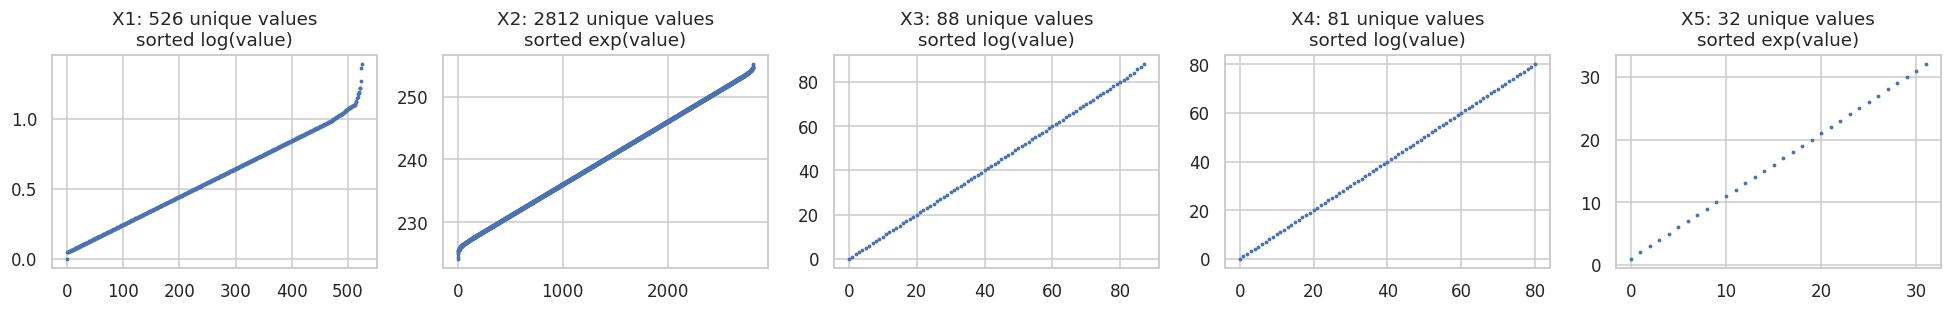

X1: transformed range [0.000, 1.390]  is integer grid: False   first values: [0.    0.046 0.048 0.05  0.052 0.054]
X3: transformed range [0.000, 88.000]  is integer grid: True   first values: [0. 1. 2. 3. 4. 5.]
X4: transformed range [0.000, 80.000]  is integer grid: True   first values: [0. 1. 2. 3. 4. 5.]
X5: transformed range [1.000, 32.000]  is integer grid: True   first values: [1. 2. 3. 4. 5. 6.]
X2: transformed range [224.200, 255.150]  is integer grid: False   first values: [224.2  224.49 224.99 225.19 225.42 225.44]


In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, c in zip(axes, ['X1', 'X2', 'X3', 'X4', 'X5']):
    v = np.sort(train[c].unique())
    ax.plot(np.log(np.clip(v, 1e-300, None)) if c in ('X1', 'X3', 'X4') else np.exp(v), '.', ms=3)
    ax.set_title(f'{c}: {len(v)} unique values\n' + ('sorted log(value)' if c in ('X1', 'X3', 'X4') else 'sorted exp(value)'))
plt.tight_layout(); plt.show()

for c, f in [('X1', np.log), ('X3', np.log), ('X4', np.log), ('X5', np.exp), ('X2', np.exp)]:
    v = f(np.clip(train[c].unique(), 1e-300, None))
    print(f'{c}: transformed range [{v.min():.3f}, {v.max():.3f}]  '
          f'is integer grid: {np.allclose(v, np.round(v))}   first values: {np.round(np.sort(v)[:6], 4)}')

The "outliers" are an artefact of an **exponential transform** applied by the data provider:

| column | decoding | decoded meaning |
|---|---|---|
| `X1` | `log(X1)` | 0 … 1.39 on a 0.002 grid (a small analogue reading) |
| `X2` | `exp(X2)` | 224 … 255 — looks like a **mains voltage** (~240 V) |
| `X3`, `X4` | `log(X3)`, `log(X4)` | integers 0 … 88 / 0 … 80 (counters / discrete levels) |
| `X5` | `exp(X5)` | integers 1 … 32 (a discrete state / level) |

After decoding there are **no extreme outliers** left — the 1e38 values are simply `exp(88)`. Clipping or removing them would
have thrown away exactly the rows where anomalies live (see below). Decision: *decode, don't clip*; tree models are invariant to
monotone transforms anyway, and for distance/linear models (KNN, SVM, LR, NN) we additionally apply a quantile→normal transform.

In [5]:
def decode(df):
    """Undo the provider's exp/log transforms (verified above: results lie on integer / regular grids)."""
    out = pd.DataFrame(index=df.index)
    out['x1'] = np.log(df['X1'])
    out['x2'] = np.exp(df['X2'])
    out['x3'] = np.round(np.log(df['X3'])).astype(int)
    out['x4'] = np.round(np.log(df['X4'])).astype(int)
    out['x5'] = np.round(np.exp(df['X5'])).astype(int)
    return out

SENS = ['x1', 'x2', 'x3', 'x4', 'x5']
dtr, dte = decode(train), decode(test)
dtr['y'] = train['target'].values
display(dtr.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
x1,1639424.0,0.124,0.113,0.0,0.048,0.10,0.194,1.39
x2,1639424.0,241.841,3.239,224.2,239.990,242.01,243.890,255.15
x3,1639424.0,1.123,6.158,0.0,0.000,0.00,0.000,88.00
x4,1639424.0,1.303,5.835,0.0,0.000,0.00,1.000,80.00
x5,1639424.0,7.454,8.435,1.0,1.000,2.00,18.000,32.00
y,1639424.0,0.009,0.092,0.0,0.000,0.00,0.000,1.00


### 2.1 Dates: month/day swap and the 1-minute grid

In [6]:
blocks = train['Date'][train['Date'].ne(train['Date'].shift())]
print('Number of date blocks in file order:', len(blocks), ' unique dates:', train['Date'].nunique())
print('First 30 blocks in file order:', blocks.dt.strftime('%Y-%m-%d').head(30).tolist())
print('Test file has identical block sequence:',
      (test['Date'][test['Date'].ne(test['Date'].shift())].values == blocks.values).all())

Number of date blocks in file order: 1432  unique dates: 1432
First 30 blocks in file order: ['2020-12-16', '2020-12-17', '2020-12-18', '2020-12-19', '2020-12-20', '2020-12-21', '2020-12-22', '2020-12-23', '2020-12-24', '2020-12-25', '2020-12-26', '2020-12-27', '2020-12-28', '2020-12-29', '2020-12-30', '2020-12-31', '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01', '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01', '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01', '2021-01-13', '2021-01-14']
Test file has identical block sequence: True


The file is grouped in day blocks, but after `2021-01-01` come `2021-02-01, 2021-03-01, …, 2021-12-01` and then `2021-01-13`:
the dates with day ≤ 12 were parsed **month-first** (they are really 1–12 January). The file order is the true chronological
order, so we fix the calendar by walking the blocks and taking whichever of {original, day/month swapped} keeps time increasing.

In [7]:
def fix_dates(df):
    """Return (day_block_id, corrected_date) for every row."""
    blk = (df['Date'] != df['Date'].shift()).cumsum() - 1
    firsts = df['Date'].groupby(blk).first()
    prev, fixed = None, []
    for d in firsts:
        cands = [d]
        if d.day <= 12:
            try: cands.append(pd.Timestamp(year=d.year, month=d.day, day=d.month))
            except ValueError: pass
        if prev is not None:
            cands = [c for c in cands if c > prev] or cands
            d = min(cands, key=lambda c: abs((c - prev).days))
        fixed.append(d); prev = d
    return blk.values, pd.Series(fixed).values[blk.values]

dtr['day'], dtr['date'] = fix_dates(train)
dte['day'], dte['date'] = fix_dates(test)
fd = pd.Series(dtr.groupby('day')['date'].first().values)
print('Corrected dates monotonic:', fd.is_monotonic_increasing, '| range', fd.min().date(), '->', fd.max().date())
print('Gaps between consecutive days:', fd.diff().dt.days.value_counts().to_dict())

per_day = pd.DataFrame({'train': dtr.groupby('day').size(), 'test': dte.groupby('day').size()})
per_day['total'] = per_day.sum(1)
print('\nRows per day:'); display(per_day.describe().T.round(1))
print('Median test share per day:', round(float((per_day.test / per_day.total).median()), 3))

Corrected dates monotonic: True | range 2020-12-16 -> 2024-11-26
Gaps between consecutive days: {1.0: 1425, 2.0: 4, 5.0: 1, 3.0: 1}

Rows per day:


,count,mean,std,min,25%,50%,75%,max
train,1432.0,1144.8,88.8,19.0,1141.0,1152.0,1162.0,2289.0
test,1432.0,286.2,26.3,2.0,277.0,288.0,298.0,591.0
total,1432.0,1431.1,109.2,21.0,1440.0,1440.0,1440.0,2880.0


Median test share per day: 0.2


* Train + test together give a median of **1 440 rows per day = one reading per minute**.
* Every day is split ~80 / 20 between train and test → the test set is a **random sample of minutes from the same days**, not a
  future period. A model can (and should) use the temporal neighbourhood of each test minute — including the labelled
  training minutes right next to it.

### 2.2 Is the row order meaningful?

In [8]:
rows = []
for c in SENS:
    rows.append({'sensor': c, 'lag-1 autocorr (file order)': dtr[c].autocorr(1),
                 'lag-1 autocorr (shuffled)': dtr[c].sample(frac=1, random_state=0).reset_index(drop=True).autocorr(1)})
display(pd.DataFrame(rows).round(3))
y = dtr['y']
print(f'P(y=1) = {y.mean():.4f}   P(y=1 | previous row y=1) = {y[y.shift(1) == 1].mean():.3f}'
      f'   P(y=1 | 2 rows before y=1) = {y[y.shift(2) == 1].mean():.3f}')
runs = y.groupby((y != y.shift()).cumsum()).agg(['first', 'size'])
rl = runs[runs['first'] == 1]['size']
print(f'Anomaly episodes: {len(rl)}, mean length {rl.mean():.2f} rows, median {rl.median():.0f}, max {rl.max()}')

,sensor,lag-1 autocorr (file order),lag-1 autocorr (shuffled)
0,x1,0.915,-0.000
1,x2,0.979,0.001
2,x3,0.894,-0.001
3,x4,0.929,0.002
4,x5,0.979,-0.000


P(y=1) = 0.0086   P(y=1 | previous row y=1) = 0.740   P(y=1 | 2 rows before y=1) = 0.612
Anomaly episodes: 3656, mean length 3.84 rows, median 2, max 62


Within each file the rows are in **chronological order**: sensors are highly autocorrelated in file order (≈0 when shuffled), and
anomalies come in **episodes** (P(anomaly | previous row anomalous) = 0.74 vs. a base rate of 0.009). This is the key insight of
the notebook — we are labelling a time series.

### 2.3 Univariate distributions and the anomaly signature

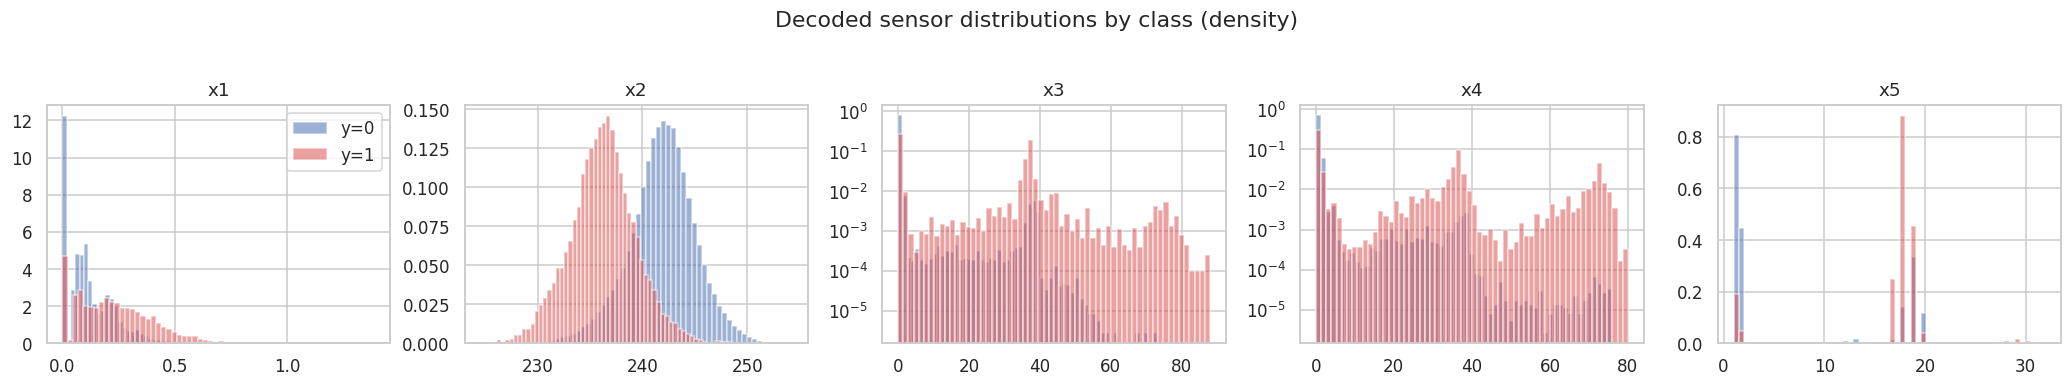

y                0        1
x1 mean      0.123    0.235
   median    0.100    0.216
x2 mean    241.889  236.203
   median  242.040  236.230
x3 mean      0.936   22.757
   median    0.000   36.000
x4 mean      1.099   24.895
   median    0.000   25.000
x5 mean      7.378   16.248
   median    2.000   18.000

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
s = dtr.sample(min(300_000, len(dtr)), random_state=0)
s = pd.concat([s, dtr[dtr.y == 1]]).drop_duplicates()
for ax, c in zip(axes, SENS):
    for lab, col in [(0, '#4C72B0'), (1, '#DD5555')]:
        v = s.loc[s.y == lab, c]
        ax.hist(v, bins=60, density=True, alpha=0.55, color=col, label=f'y={lab}')
    ax.set_title(c); ax.set_yscale('log' if c in ('x3', 'x4') else 'linear')
axes[0].legend(); plt.suptitle('Decoded sensor distributions by class (density)', y=1.03); plt.tight_layout(); plt.show()
display(dtr.groupby('y')[SENS].agg(['mean', 'median']).T.round(3))

Anomalous minutes show **lower voltage `x2`** (236 vs 242), **higher `x1`**, **non-zero `x3`/`x4` counters** (median 36 / 25 vs 0)
and `x5` concentrated around 17–19. No single sensor separates the classes, but they move together.

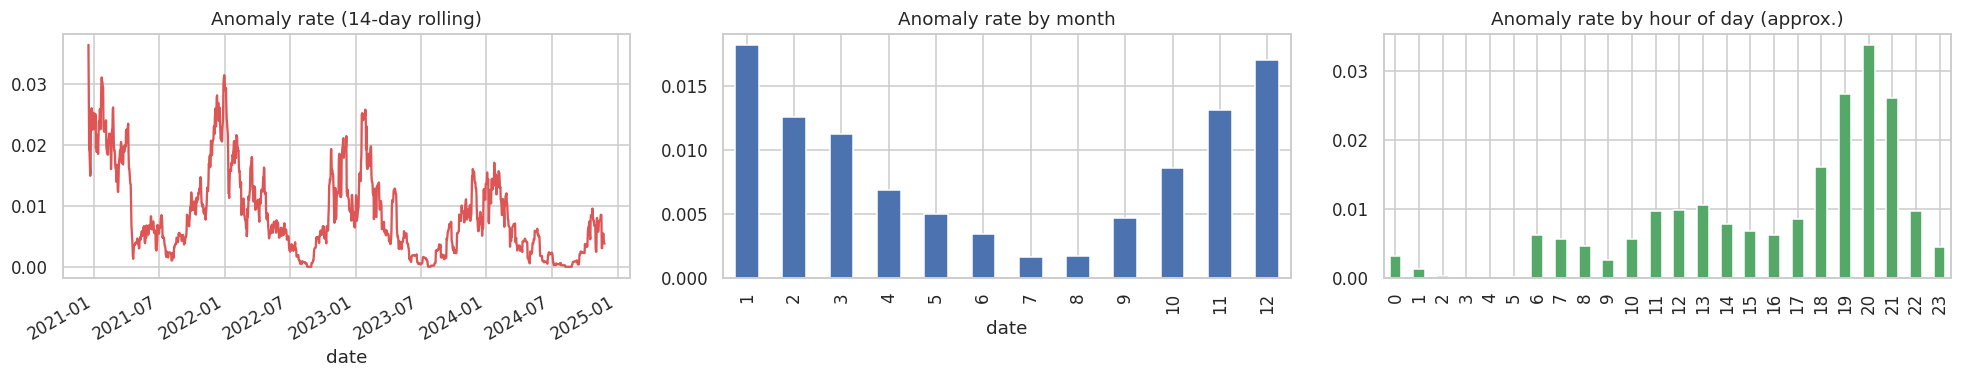

      anomaly_rate    size
date                      
2020      0.024345   17622
2021      0.012572  417268
2022      0.008575  421434
2023      0.007332  417068
2024      0.004620  366032


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
dd = dtr.groupby('date')['y'].mean()
dd.rolling(14, min_periods=1).mean().plot(ax=axes[0], color='#DD5555'); axes[0].set_title('Anomaly rate (14-day rolling)')
dtr.groupby(pd.to_datetime(dtr['date']).dt.month)['y'].mean().plot.bar(ax=axes[1], color='#4C72B0'); axes[1].set_title('Anomaly rate by month')
pos_in_day = dtr.groupby('day').cumcount() / dtr.groupby('day')['y'].transform('size') * 24
dtr.groupby(pos_in_day.astype(int))['y'].mean().plot.bar(ax=axes[2], color='#55A868'); axes[2].set_title('Anomaly rate by hour of day (approx.)')
plt.tight_layout(); plt.show()
print(dtr.groupby(pd.to_datetime(dtr['date']).dt.year)['y'].agg(['mean', 'size']).rename(columns={'mean': 'anomaly_rate'}))

* The anomaly rate **drifts down** over the years (2.4 % in Dec-2020 → 0.46 % in 2024) and is **seasonal** (winter ≈ 3× summer) and
  has a **daily cycle** — so calendar features are useful and a temporal backtest is needed to check stability.

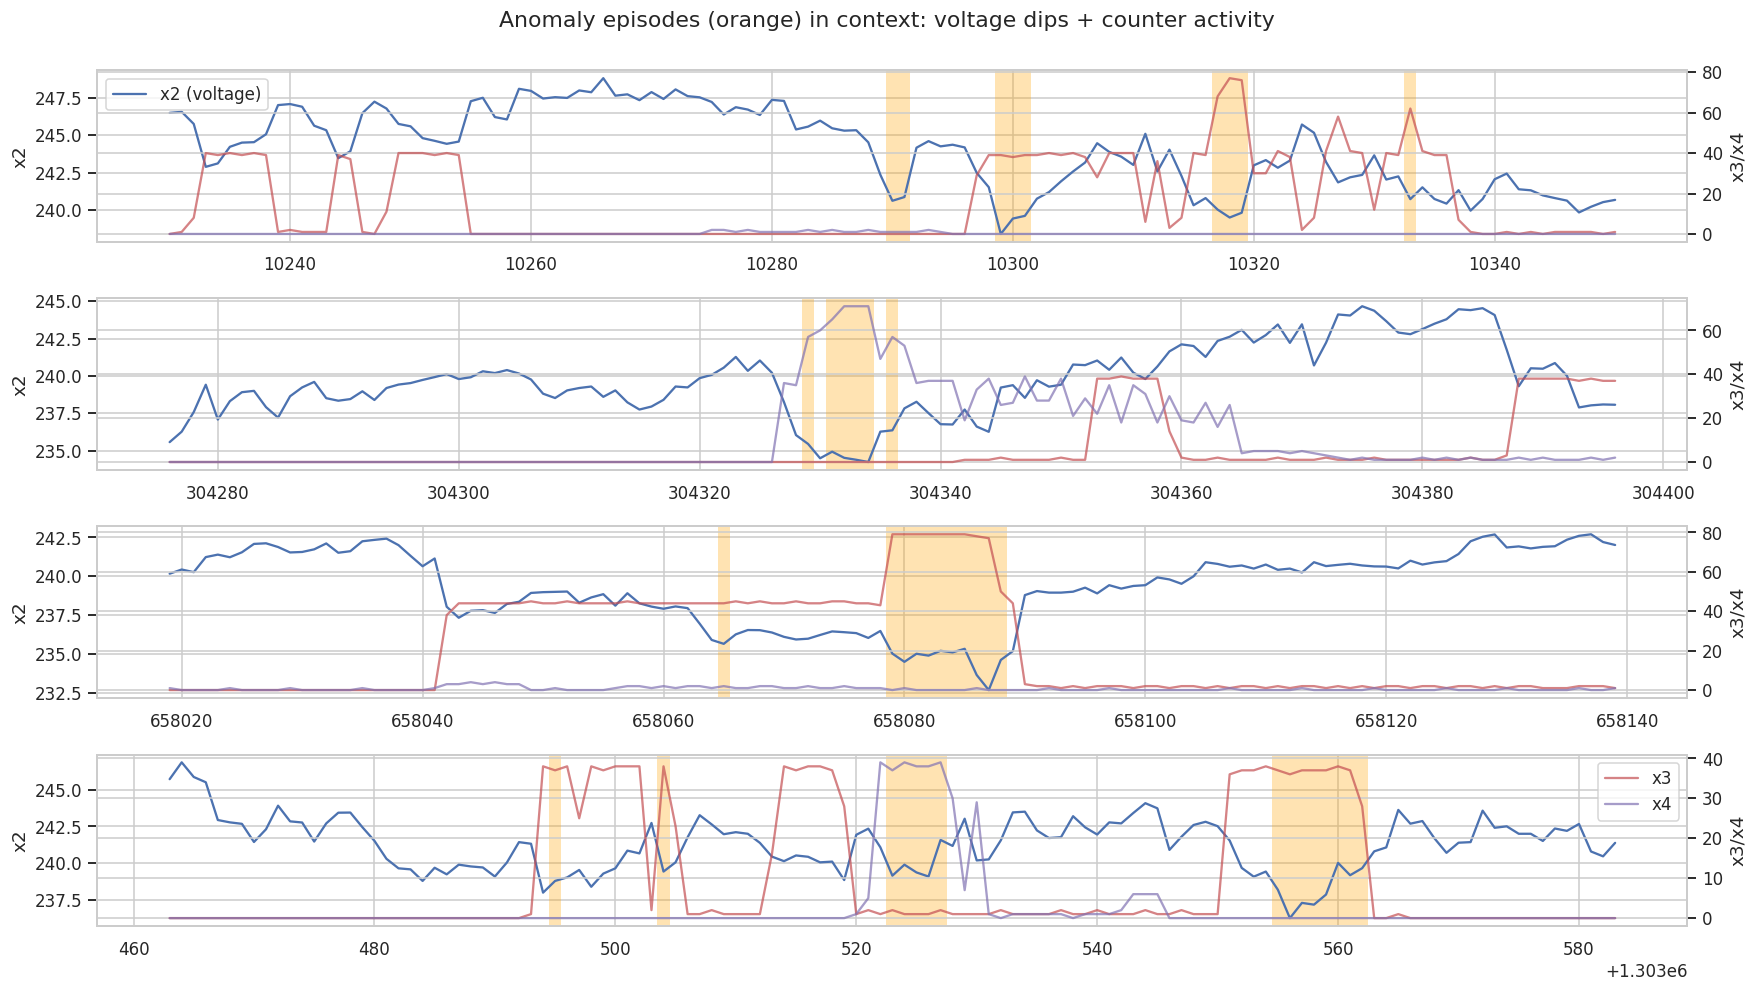

In [11]:
# a few anomaly episodes in context (file order = time order)
idx = dtr.index[dtr.y.eq(1) & dtr.y.shift(1).eq(0)].values
fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=False)
for ax, i in zip(axes, idx[(np.array([.02, .25, .55, .9]) * len(idx)).astype(int)]):
    w = dtr.loc[i - 60:i + 60]
    ax.plot(w.index, w.x2, color='#4C72B0', label='x2 (voltage)')
    ax2 = ax.twinx(); ax2.plot(w.index, w.x3, color='#C44E52', alpha=.7, label='x3'); ax2.plot(w.index, w.x4, color='#8172B2', alpha=.7, label='x4')
    for j in w.index[w.y == 1]: ax.axvspan(j - .5, j + .5, color='orange', alpha=.3, lw=0)
    ax.set_ylabel('x2'); ax2.set_ylabel('x3/x4')
axes[0].legend(loc='upper left'); ax2.legend(loc='upper right')
plt.suptitle('Anomaly episodes (orange) in context: voltage dips + counter activity', y=1.0); plt.tight_layout(); plt.show()

### 2.4 Correlation analysis

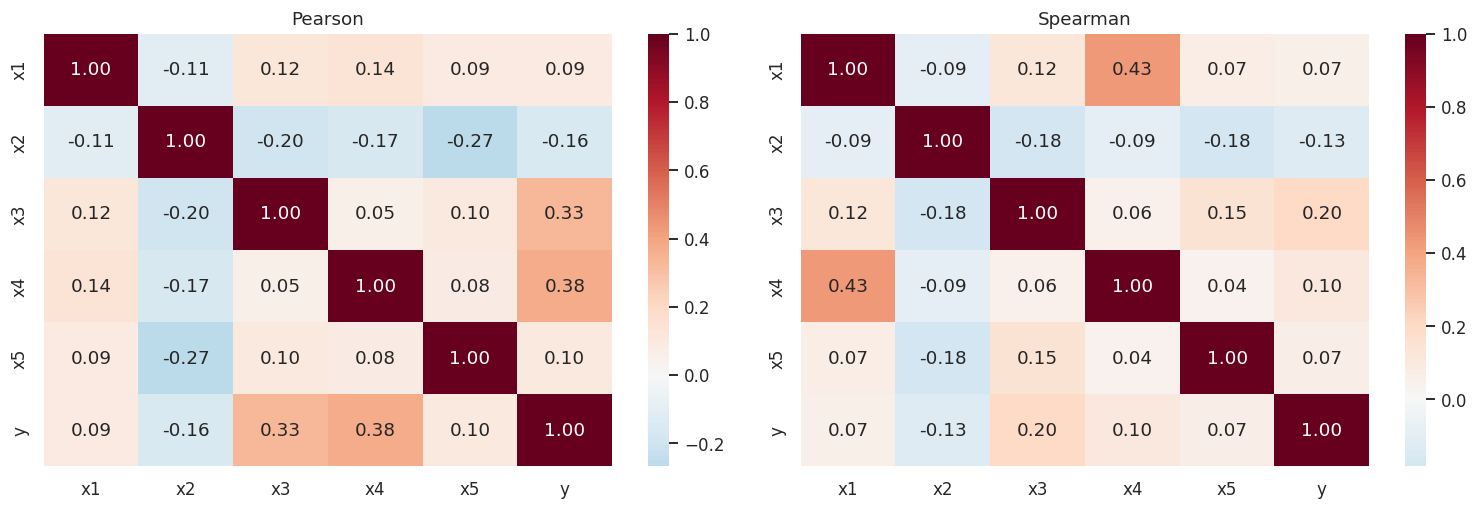

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(dtr[SENS + ['y']].corr(method='pearson'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[0]); axes[0].set_title('Pearson')
sns.heatmap(dtr[SENS + ['y']].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1]); axes[1].set_title('Spearman')
plt.tight_layout(); plt.show()

Raw point-wise correlations with the target are modest (|ρ| ≤ 0.3), `x3`–`x4` and `x1`–`x5` are inter-correlated. The weak
point-wise signal confirms that **context** (how a reading deviates from its neighbourhood) is where the information is.

## 3. Reconstructing the 1-minute timeline (train ⟷ test interleaving)

For each day we know the **order of the train minutes** and the **order of the test minutes**, but not how the two sequences
interleave. Sensors are smooth in time, so the true interleaving is the one with the smallest total "jump" between consecutive
readings. This is an *optimal merge of two ordered sequences* and can be solved **exactly** with dynamic programming
(state = (#train placed, #test placed, which sequence the last row came from); O(n·m) per day, compiled with `numba`).

Cost of placing row *b* after row *a*: weighted L1 distance of standardised decoded sensors (weights 1, 2, .5, .5, 1 for
x1…x5 — `x2` is the smoothest signal).

In [13]:
@numba.njit(cache=True)
def _merge_two(A, B, w):
    """Optimal interleaving of ordered sequences A and B minimising sum_t w·|r_t - r_{t-1}|. Returns src[k] in {0:A, 1:B}."""
    n, m, nf, INF = A.shape[0], B.shape[0], A.shape[1], 1e18
    C = np.full((n + 1, m + 1, 2), INF); P = np.zeros((n + 1, m + 1, 2), np.int8)
    if n > 0: C[1, 0, 0] = 0.0
    if m > 0: C[0, 1, 1] = 0.0
    for i in range(n + 1):
        for j in range(m + 1):
            for k in range(2):
                c = C[i, j, k]
                if c >= INF: continue
                last = A[i - 1] if k == 0 else B[j - 1]
                if i < n:
                    v = c
                    for t in range(nf): v += w[t] * abs(last[t] - A[i, t])
                    if v < C[i + 1, j, 0]: C[i + 1, j, 0] = v; P[i + 1, j, 0] = k
                if j < m:
                    v = c
                    for t in range(nf): v += w[t] * abs(last[t] - B[j, t])
                    if v < C[i, j + 1, 1]: C[i, j + 1, 1] = v; P[i, j + 1, 1] = k
    k = 0 if C[n, m, 0] <= C[n, m, 1] else 1
    i, j, L = n, m, n + m
    src = np.empty(n + m, np.int8)
    while i + j > 0:                       # back-track
        L -= 1; src[L] = k; pk = P[i, j, k]
        if k == 0: i -= 1
        else: j -= 1
        k = pk
    return src

MERGE_W = np.array([1.0, 2.0, 0.5, 0.5, 1.0])

def merge_timeline(SA, dayA, SB, dayB):
    """Merge two day-sorted sequences day by day; returns global timeline positions of every A row and B row."""
    posA, posB = np.empty(len(SA), np.int64), np.empty(len(SB), np.int64)
    days = np.union1d(dayA, dayB)
    ia0, ia1 = np.searchsorted(dayA, days, 'left'), np.searchsorted(dayA, days, 'right')
    ib0, ib1 = np.searchsorted(dayB, days, 'left'), np.searchsorted(dayB, days, 'right')
    off = 0
    for a0, a1, b0, b1 in zip(ia0, ia1, ib0, ib1):
        src = _merge_two(SA[a0:a1], SB[b0:b1], MERGE_W)
        k = np.arange(len(src)) + off
        posA[a0:a1], posB[b0:b1] = k[src == 0], k[src == 1]
        off += len(src)
    return posA, posB

# standardise decoded sensors with joint train+test statistics (label-free)
_all = np.vstack([dtr[SENS].to_numpy(float), dte[SENS].to_numpy(float)])
MU, SD = _all.mean(0), _all.std(0)
Str = (dtr[SENS].to_numpy(float) - MU) / SD
Ste = (dte[SENS].to_numpy(float) - MU) / SD
day_tr, day_te = dtr['day'].values, dte['day'].values

**Does it work?** We can measure it on the training file, where the true order is known: hide a random 20 % of the train minutes
of 150 days, re-insert them with the DP, and compare the recovered positions with the truth. Baseline = "spread the hidden
rows uniformly over the day".

In [14]:
rng = np.random.default_rng(1)
err_dp, err_uni = [], []
for d in rng.choice(dtr['day'].max() + 1, min(150, dtr['day'].max() + 1), replace=False):
    idx = np.flatnonzero(day_tr == d); N = len(idx)
    hid = rng.random(N) < 0.2
    src = _merge_two(Str[idx[~hid]], Str[idx[hid]], MERGE_W)
    true_pos = np.flatnonzero(hid)
    err_dp.append(np.abs(np.flatnonzero(src == 1) - true_pos))
    err_uni.append(np.abs((np.arange(hid.sum()) + .5) / hid.sum() * N - true_pos))
err_dp, err_uni = np.concatenate(err_dp), np.concatenate(err_uni)
print(pd.DataFrame({'DP alignment': [err_dp.mean(), np.median(err_dp), (err_dp <= 1).mean(), (err_dp <= 3).mean()],
                    'uniform spread': [err_uni.mean(), np.median(err_uni), (err_uni <= 1).mean(), (err_uni <= 3).mean()]},
                   index=['mean |error| (rows)', 'median |error|', 'share within ±1', 'share within ±3']).round(3))

                     DP alignment  uniform spread
mean |error| (rows)         1.763          21.759
median |error|              1.000          16.904
share within ±1             0.646           0.037
share within ±3             0.855           0.108


The DP recovers the position of a hidden minute with a **median error of ~1 row** (the remaining ambiguity is mostly between
near-identical consecutive readings), versus ~16 rows for the naive spread. Good enough to compute rolling features on the full
1-minute grid and to find each test minute's labelled neighbours.

## 4. Feature engineering

All features are computed on the reconstructed timeline (train + test minutes together).

**A. Sensor-context features (label-free)** — for each decoded sensor:
* lags/leads (1–3 steps) as differences to the current value;
* centred rolling mean / std / min / max over 5, 15, 61, 241 minutes, and the **deviation** of the reading from its rolling mean;
* past-only and future-only window deviations (onset vs. recovery of an event), EWM residual;
* day-level mean / std / z-score / percentile rank;
* voltage-drop features (`x2` vs. its recent max), counter run lengths (`x3`, `x4` > 0), `x1 == 0` density;
* calendar: minute-of-day, month, day-of-year, weekday, trend (days since start), rows per day.

**B. Neighbour-label features (leave-self-out)** — anomalies come in episodes, so the labels of the *labelled* minutes around a
row are very informative: mean label of the k previous / next / both-side labelled minutes (k = 1…120), timeline distance to
the nearest labelled anomaly, gap to the nearest labelled minute, and the day's anomaly rate. A row's **own label is never
used**; for a test row all its labelled neighbours are training rows — exactly what is available at prediction time.

**Leakage control / train–test consistency.** Training rows sit at exact positions with all other train labels visible, but
test rows are placed by the DP and see neighbours through a noisier placement. To make the training features *look like*
test features we generate them **out-of-fold**: split train into 10 chunks; for each chunk, hide its labels and positions,
re-insert it with the DP (then insert the test rows), and compute its features from the remaining 90 % of labels.

### 4.0 Soft (posterior) alignment — handling the ±1-minute ambiguity

The DP gives the single best interleaving, but around episode boundaries a one-minute shift flips the neighbour-label features
(~60 % of the remaining errors sit there). We therefore also run a **forward–backward pass over the same lattice** with path
weights `exp(-cost / T)` (T = 1). For every unlabelled minute this yields the posterior probability of each possible slot between
labelled minutes, and from it **expected neighbour labels** (`s_prev*`, `s_next*`, `s_both*`), the probability of sitting inside
an episode or on its boundary, and the alignment uncertainty (max-probability, entropy, std of the slot).

On the hold-out, `s_both1` alone reaches PR-AUC 0.886 versus 0.722 for its hard-alignment counterpart; in the full LightGBM
it lifts anomaly-F1 from 0.8836 to 0.8866.

In [15]:
SOFT_T = 1.0          # temperature (best of 0.05 / 0.15 / 0.4 / 1 / 2 / 4 on the hold-out)
KS = (1, 2, 3, 5, 10, 30)
SOFT_NAMES = ([f's_prev{k}' for k in KS] + [f's_next{k}' for k in KS] + [f's_both{k}' for k in KS] +
              ['s_inside', 's_boundary', 's_pmax', 's_entropy', 's_pos_std'])
NF = len(SOFT_NAMES)


@numba.njit(cache=True)
def _lae(a, b):
    if a == -np.inf:
        return b
    if b == -np.inf:
        return a
    if a > b:
        return a + np.log1p(np.exp(b - a))
    return b + np.log1p(np.exp(a - b))


@numba.njit(cache=True)
def _dist(x, y, w):
    s = 0.0
    for t in range(x.shape[0]):
        s += w[t] * abs(x[t] - y[t])
    return s


@numba.njit(cache=True)
def soft_day(A, B, yA, w, T):
    n, m = A.shape[0], B.shape[0]
    out = np.full((m, 23), np.nan)
    if m == 0 or n == 0:
        return out
    NI = -np.inf
    F = np.full((n + 1, m + 1, 2), NI)
    G = np.full((n + 1, m + 1, 2), NI)
    F[1, 0, 0] = 0.0
    F[0, 1, 1] = 0.0
    for i in range(n + 1):                      # forward (push)
        for j in range(m + 1):
            for k in range(2):
                v = F[i, j, k]
                if v == NI:
                    continue
                last = A[i - 1] if k == 0 else B[j - 1]
                if i < n:
                    F[i + 1, j, 0] = _lae(F[i + 1, j, 0], v - _dist(last, A[i], w) / T)
                if j < m:
                    F[i, j + 1, 1] = _lae(F[i, j + 1, 1], v - _dist(last, B[j], w) / T)
    G[n, m, 0] = 0.0
    G[n, m, 1] = 0.0
    for i in range(n, -1, -1):                  # backward
        for j in range(m, -1, -1):
            for k in range(2):
                if i == n and j == m:
                    continue
                if (k == 0 and i == 0) or (k == 1 and j == 0):
                    continue
                last = A[i - 1] if k == 0 else B[j - 1]
                v = NI
                if i < n:
                    v = _lae(v, G[i + 1, j, 0] - _dist(last, A[i], w) / T)
                if j < m:
                    v = _lae(v, G[i, j + 1, 1] - _dist(last, B[j], w) / T)
                G[i, j, k] = v
    logZ = _lae(F[n, m, 0], F[n, m, 1])
    CS = np.zeros(n + 1)
    for i in range(n):
        CS[i + 1] = CS[i] + yA[i]
    P = np.empty(n + 1)
    for j in range(m):
        tot = 0.0
        for i in range(n + 1):
            P[i] = np.exp(F[i, j + 1, 1] + G[i, j + 1, 1] - logZ)
            tot += P[i]
        if tot <= 0:
            continue
        for i in range(n + 1):
            P[i] /= tot
        acc = np.zeros(23)
        pmax = 0.0; ent = 0.0; mu = 0.0; m2 = 0.0
        for i in range(n + 1):
            p = P[i]
            if p < 1e-9:
                continue
            for q in range(6):
                k = KS[q]
                lo = max(i - k, 0); hi = min(i + k, n)
                pv = (CS[i] - CS[lo]) / max(i - lo, 1)
                nv = (CS[hi] - CS[i]) / max(hi - i, 1)
                bv = (CS[i] - CS[lo] + CS[hi] - CS[i]) / max(hi - lo, 1)
                acc[q] += p * pv; acc[6 + q] += p * nv; acc[12 + q] += p * bv
            yp = yA[i - 1] if i > 0 else 0.0
            yn = yA[i] if i < n else 0.0
            acc[18] += p * yp * yn                     # sits inside a labelled episode
            acc[19] += p * (yp + yn - 2 * yp * yn)     # sits on an episode boundary
            if p > pmax:
                pmax = p
            ent -= p * np.log(p)
            mu += p * i; m2 += p * i * i
        acc[20] = pmax; acc[21] = ent; acc[22] = np.sqrt(max(m2 - mu * mu, 0.0))
        out[j] = acc
    return out


def soft_features(SA, dayA, yA, SB, dayB, w, T):
    """SA/SB standardised sensors (day-sorted, own order), yA labels of A. Returns (len(SB), NF)."""
    out = np.full((len(SB), NF), np.nan, np.float32)
    days = np.union1d(dayA, dayB)
    ia0, ia1 = np.searchsorted(dayA, days, 'left'), np.searchsorted(dayA, days, 'right')
    ib0, ib1 = np.searchsorted(dayB, days, 'left'), np.searchsorted(dayB, days, 'right')
    for a0, a1, b0, b1 in zip(ia0, ia1, ib0, ib1):
        if b1 > b0:
            out[b0:b1] = soft_day(SA[a0:a1], SB[b0:b1], yA[a0:a1].astype(np.float64), w, T)
    return out

In [16]:
def _run_len(b):
    out = np.zeros(len(b), np.int64); run = 0
    for i, v in enumerate(b):
        run = run + 1 if v else 0; out[i] = run
    return out

class _Store(dict):
    """dict that keeps only the requested rows, as float32 (keeps peak memory low)."""
    def __init__(self, keep): super().__init__(); self.keep = keep
    def __setitem__(self, k, v): super().__setitem__(k, np.asarray(v, dtype=np.float32)[self.keep])

def sensor_features(tl, keep):
    f = _Store(keep)
    for c in SENS:
        s = tl[c].astype(float); f[c] = s
        for k in (1, 2, 3):
            f[f'{c}_lag{k}'] = s.shift(k) - s; f[f'{c}_lead{k}'] = s.shift(-k) - s
        for w in (5, 15, 61, 241):
            r = s.rolling(w, center=True, min_periods=1); m = r.mean()
            f[f'{c}_m{w}'] = m; f[f'{c}_dev{w}'] = s - m; f[f'{c}_s{w}'] = r.std()
            if w in (5, 15, 61): f[f'{c}_mx{w}'] = r.max(); f[f'{c}_mn{w}'] = r.min()
        for w in (15, 61):
            f[f'{c}_pdev{w}'] = s - s.rolling(w, min_periods=1).mean()                  # vs. past window
            f[f'{c}_fdev{w}'] = s - s[::-1].rolling(w, min_periods=1).mean()[::-1]      # vs. future window
        f[f'{c}_ewm'] = s - s.ewm(span=10).mean()
        g = s.groupby(tl['day']); dm, ds = g.transform('mean'), g.transform('std')
        f[f'{c}_daymean'] = dm; f[f'{c}_daystd'] = ds
        f[f'{c}_dayz'] = (s - dm) / (ds + 1e-9); f[f'{c}_dayrank'] = g.rank(pct=True)
    x2 = tl['x2']
    for w in (15, 61):
        f[f'x2_drop_past{w}'] = x2.rolling(w, min_periods=1).max() - x2
        f[f'x2_drop_fut{w}'] = x2[::-1].rolling(w, min_periods=1).max()[::-1] - x2
    f['x2_absdiff_s15'] = x2.diff().abs().rolling(15, center=True, min_periods=1).mean()
    f['x3_pos'] = (tl['x3'] > 0).astype(int); f['x4_pos'] = (tl['x4'] > 0).astype(int)
    f['x34'] = tl['x3'] + tl['x4']
    f['x3_runlen'] = _run_len(tl['x3'].to_numpy() > 0); f['x4_runlen'] = _run_len(tl['x4'].to_numpy() > 0)
    f['x3_runlen_b'] = _run_len(tl['x3'].to_numpy()[::-1] > 0)[::-1]; f['x4_runlen_b'] = _run_len(tl['x4'].to_numpy()[::-1] > 0)[::-1]
    is1 = (tl['x1'] == 0).astype(int); f['x1_is1'] = is1
    f['x1_is1_m61'] = is1.rolling(61, center=True, min_periods=1).mean()
    dt = pd.to_datetime(tl['date'])
    f['minute'] = tl['minute']; f['month'] = dt.dt.month; f['doy'] = dt.dt.dayofyear; f['dow'] = dt.dt.dayofweek
    f['t_days'] = (dt - dt.min()).dt.days; f['day_n'] = tl.groupby('day')['x1'].transform('size')
    return pd.DataFrame(dict(f), index=tl.index[keep])

def label_features(pos_all, lab_pos, lab_y, day_all, lab_day):
    """Neighbour-label features from labelled rows only; a row's own label is always excluded."""
    o = np.argsort(lab_pos); P, Y = lab_pos[o], lab_y[o].astype(float)
    CS = np.r_[0, np.cumsum(Y)]; n = len(P)
    kb = np.searchsorted(P, pos_all, 'left')      # labelled rows strictly before
    ka = np.searchsorted(P, pos_all, 'right')     # labelled rows strictly after
    f = {}
    for k in (1, 2, 3, 5, 10, 30, 120):
        lo, hi = np.maximum(kb - k, 0), np.minimum(ka + k, n)
        f[f'yprev{k}'] = (CS[kb] - CS[lo]) / np.maximum(kb - lo, 1)
        f[f'ynext{k}'] = (CS[hi] - CS[ka]) / np.maximum(hi - ka, 1)
        f[f'yboth{k}'] = (CS[kb] - CS[lo] + CS[hi] - CS[ka]) / np.maximum(kb - lo + hi - ka, 1)
    f['gap_prev'] = np.where(kb > 0, pos_all - P[np.maximum(kb - 1, 0)], 999)
    f['gap_next'] = np.where(ka < n, P[np.minimum(ka, n - 1)] - pos_all, 999)
    AP = P[Y == 1]
    jb, ja = np.searchsorted(AP, pos_all, 'left'), np.searchsorted(AP, pos_all, 'right')
    f['dist_prev_anom'] = np.where(jb > 0, pos_all - AP[np.maximum(jb - 1, 0)], 10**6).clip(max=5000)
    f['dist_next_anom'] = np.where(ja < len(AP), AP[np.minimum(ja, len(AP) - 1)] - pos_all, 10**6).clip(max=5000)
    f['dist_anom'] = np.minimum(f['dist_prev_anom'], f['dist_next_anom'])
    f = pd.DataFrame(f)
    lab_df = pd.DataFrame({'day': lab_day, 'y': lab_y})
    s = pd.Series(day_all).map(lab_df.groupby('day')['y'].sum()).fillna(0).to_numpy()
    c = pd.Series(day_all).map(lab_df.groupby('day')['y'].size()).fillna(0).to_numpy()
    is_lab = np.isin(pos_all, P)
    self_y = np.zeros(len(pos_all)); idx = np.minimum(np.searchsorted(P, pos_all), n - 1)
    self_y[is_lab] = Y[idx[is_lab]]
    f['day_rate'] = (s - self_y) / np.maximum(c - is_lab, 1)        # leave-self-out daily anomaly rate
    return f

def build_view(lab_idx, hidden_groups, want_idx, with_test=False):
    """One 'view' of the data.
    lab_idx       : train rows whose order and label are known.
    hidden_groups : list of train-row index arrays inserted by DP (in turn) with labels hidden; then the test rows.
    want_idx      : train rows to return (None -> return the test rows); with_test=True also returns the test rows."""
    seq = np.sort(lab_idx)
    for g in hidden_groups:
        g = np.sort(g)
        pa, pb = merge_timeline(Str[seq], day_tr[seq], Str[g], day_tr[g])
        allr = np.r_[seq, g]; seq = allr[np.argsort(np.r_[pa, pb], kind='stable')]
    p1, p2 = merge_timeline(Str[seq], day_tr[seq], Ste, day_te)
    pos_tr = np.empty(len(dtr), np.int64); pos_tr[seq] = p1
    tl = pd.concat([dtr.assign(pos=pos_tr, row=np.arange(len(dtr)), tid=-1, src='train'),
                    dte.assign(pos=p2, row=-1, tid=np.arange(len(dte)), src='test', y=np.nan)], ignore_index=True)
    tl['is_lab'] = False; tl.loc[lab_idx, 'is_lab'] = True
    tl = tl.sort_values('pos').reset_index(drop=True)
    tl['minute'] = tl.groupby('day').cumcount() / tl.groupby('day')['x1'].transform('size') * 1440
    keep = np.isin(tl['row'].values, want_idx) if want_idx is not None else (tl['src'] == 'test').values
    if with_test: keep = keep | (tl['src'] == 'test').values
    F = sensor_features(tl, keep)
    lab = tl[tl.is_lab]
    LF = label_features(tl['pos'].values, lab['pos'].values, lab['y'].values, tl['day'].values, lab['day'].values)
    LF.index = tl.index
    res = pd.concat([tl.loc[keep, ['row', 'tid', 'pos', 'day', 'date', 'src', 'y']], F, LF[keep].astype(np.float32)], axis=1)
    # soft-alignment features of the wanted rows relative to the labelled rows
    L = np.sort(lab_idx); is_t = (res['src'] == 'test').values
    out = np.full((len(res), len(SOFT_NAMES)), np.nan, np.float32)
    if want_idx is None or with_test:
        SFt = pd.DataFrame(soft_features(Str[L], day_tr[L], dtr['y'].values[L], Ste, day_te, MERGE_W, SOFT_T),
                           columns=SOFT_NAMES, index=np.arange(len(dte)))
        out[is_t] = SFt.reindex(res.loc[is_t, 'tid'].values).values
    if want_idx is not None:
        Wd = np.sort(want_idx)
        SFr = pd.DataFrame(soft_features(Str[L], day_tr[L], dtr['y'].values[L], Str[Wd], day_tr[Wd], MERGE_W, SOFT_T),
                           columns=SOFT_NAMES, index=Wd)
        out[~is_t] = SFr.reindex(res.loc[~is_t, 'row'].values).values
    res[SOFT_NAMES] = out
    return res

def build_dataset(pool, H, K=10, seed=7, tag=''):
    """Out-of-fold, test-like features for every row in `pool`; H = extra hidden train rows (validation) or empty."""
    path = f'{CACHE}/train_{tag}.parquet'
    if os.path.exists(path): return pd.read_parquet(path)
    chunk = np.random.default_rng(seed).integers(0, K, len(pool)); parts = []
    for k in range(K):
        ck = pool[chunk == k]
        parts.append(build_view(pool[chunk != k], [ck] + ([H] if len(H) else []), ck).assign(chunk=k))
        print(f'  [{tag}] chunk {k + 1}/{K} done ({elapsed()})')
    out = pd.concat(parts).sort_values('row').reset_index(drop=True); out.to_parquet(path)
    return out

### 4.1 Validation design

The test set is a random 20 % of minutes, so the most faithful validation is to **re-create that situation inside train**:

* **Hold-out `H`** = random 20 % of the training rows. They are treated exactly like test rows (labels hidden, positions
  re-estimated by the DP). All model selection, threshold tuning and evaluation below is done on `H` — it is never used for fitting.
* **Fit pool** = the other 80 %; its features are generated out-of-fold (10 chunks) as described above.
* **Final model** = same recipe on 100 % of train, predicting the real test set.
* **Temporal backtest** (Section 8) checks stability under drift: train on earlier years, evaluate on later years.

Building the features is the expensive step (~2 × 12 min with 4 CPU cores) and is cached in `cache/`.

In [17]:
rng = np.random.default_rng(SEED)
all_rows = np.arange(len(dtr))
hide = rng.random(len(dtr)) < 0.2
POOL, H = all_rows[~hide], all_rows[hide]

fit_df = build_dataset(POOL, H, tag='sim_v2')                              # validation world: fit rows
p = f'{CACHE}/holdout_sim_v2.parquet'
if os.path.exists(p): hold_df = pd.read_parquet(p)
else: hold_df = build_view(POOL, [H], H).reset_index(drop=True); hold_df.to_parquet(p)
print('fit rows:', fit_df.shape, ' hold-out rows:', hold_df.shape, ' hold-out anomaly rate:', round(float(hold_df.y.mean()), 4), elapsed())

META = ['row', 'tid', 'pos', 'day', 'date', 'src', 'y', 'chunk']
FEATS = [c for c in fit_df.columns if c not in META]
LAB_FEATS = [c for c in FEATS if c.startswith(('yprev', 'ynext', 'yboth', 'gap_', 'dist_', 'day_rate', 's_'))]
SENS_FEATS = [c for c in FEATS if c not in LAB_FEATS]
print(f'{len(FEATS)} features: {len(SENS_FEATS)} sensor-context + {len(LAB_FEATS)} neighbour-label')
Xf, yf = fit_df[FEATS].to_numpy(np.float32), fit_df['y'].to_numpy().astype(int)
Xh, yh = hold_df[FEATS].to_numpy(np.float32), hold_df['y'].to_numpy().astype(int)

  [sim_v2] chunk 1/10 done (1.5 min)
  [sim_v2] chunk 2/10 done (2.7 min)
  [sim_v2] chunk 3/10 done (3.9 min)
  [sim_v2] chunk 4/10 done (5.1 min)
  [sim_v2] chunk 5/10 done (6.3 min)
  [sim_v2] chunk 6/10 done (7.5 min)
  [sim_v2] chunk 7/10 done (8.6 min)
  [sim_v2] chunk 8/10 done (9.8 min)
  [sim_v2] chunk 9/10 done (11.0 min)
  [sim_v2] chunk 10/10 done (12.2 min)
fit rows: (1311572, 248)  hold-out rows: (327852, 247)  hold-out anomaly rate: 0.0082 14.4 min
240 features: 190 sensor-context + 50 neighbour-label


### 4.2 Feature–target relationships

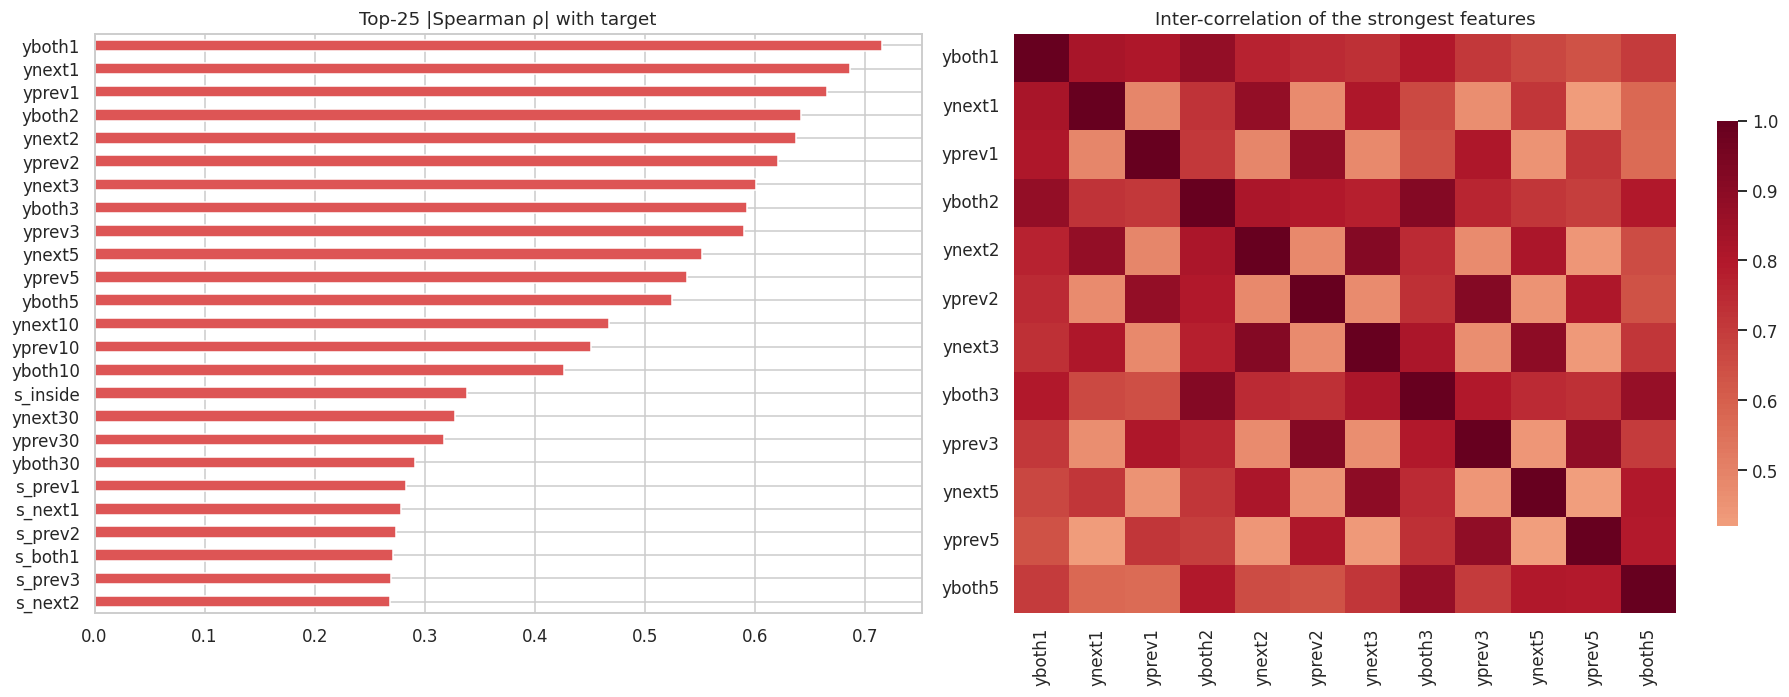

Highly redundant pairs (|ρ|>0.98) among all features: 19


In [18]:
samp = fit_df.sample(min(400_000, len(fit_df)), random_state=0)
corr = samp[FEATS].corrwith(samp['y'], method='spearman').dropna()
top = corr.abs().sort_values(ascending=False).head(25).index
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
corr[top].sort_values().plot.barh(ax=axes[0], color=np.where(corr[top].sort_values() > 0, '#DD5555', '#4C72B0'))
axes[0].set_title('Top-25 |Spearman ρ| with target')
k = [c for c in top[:12]]
sns.heatmap(samp[k].corr(method='spearman'), cmap='RdBu_r', center=0, ax=axes[1], cbar_kws={'shrink': .7})
axes[1].set_title('Inter-correlation of the strongest features'); plt.tight_layout(); plt.show()
print('Highly redundant pairs (|ρ|>0.98) among all features:',
      int(((samp[FEATS].corr().abs() > 0.98).sum().sum() - len(FEATS)) / 2))

Neighbour-label features and the local-deviation features (`x2_dev*`, rolling `x3`/`x4` levels) dominate. Many features are
redundant (expected with nested windows); gradient-boosted trees cope with that, and for the linear / distance models we rely on
regularisation + a quantile transform. We keep the full set — the importance analysis in Section 9 shows which ones matter.

## 5. Evaluation helpers

* Ranking quality: **PR-AUC** (average precision) — the right threshold-free metric under heavy imbalance — and ROC-AUC.
* Decision quality: the decision threshold is tuned to maximise the **anomaly-class F1** (equivalently macro-F1, since class-0 F1 is
  ≈0.999 for any sensible model). We report **precision / recall / F1 and per-class accuracy (= recall of that class)** for both
  classes, plus overall accuracy, macro-F1 and balanced accuracy.

In [19]:
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve, balanced_accuracy_score)

def best_threshold(y, p, grid=None):
    grid = np.unique(np.quantile(p, np.linspace(0.95, 0.999, 300))) if grid is None else grid
    f = np.array([f1_score(y, p >= t) for t in grid]); i = int(np.argmax(f))
    return float(grid[i]), float(f[i])

def class_report(y, pred):
    out = {}
    for c in (0, 1):
        out[f'precision_{c}'] = precision_score(y, pred, pos_label=c, zero_division=0)
        out[f'recall/acc_{c}'] = recall_score(y, pred, pos_label=c)
        out[f'F1_{c}'] = f1_score(y, pred, pos_label=c)
    out['accuracy'] = accuracy_score(y, pred); out['macro_F1'] = f1_score(y, pred, average='macro')
    out['balanced_acc'] = balanced_accuracy_score(y, pred)
    return out

RESULTS, HOLD_P = {}, {}
def evaluate(name, p, y=None, fit_time=None, store=True):
    y = yh if y is None else y
    t, _ = best_threshold(y, p)
    r = {'PR_AUC': average_precision_score(y, p), 'ROC_AUC': roc_auc_score(y, p), 'threshold': t, **class_report(y, p >= t)}
    if fit_time is not None: r['fit_min'] = fit_time / 60
    if store: RESULTS[name] = r; HOLD_P[name] = p
    print(f"{name:<22s} PR-AUC={r['PR_AUC']:.4f}  F1_1={r['F1_1']:.4f}  F1_0={r['F1_0']:.4f}  acc_1={r['recall/acc_1']:.4f}"
          f"  acc_0={r['recall/acc_0']:.5f}  macroF1={r['macro_F1']:.4f}  ({elapsed()})")
    return r

def results_table():
    return pd.DataFrame(RESULTS).T.sort_values('PR_AUC', ascending=False)

## 6. Classical models

Classical models need some care at this scale (1.3 M fit rows × 220 features):
* Inputs go through a **QuantileTransformer → N(0,1)** (robust to the heavy-tailed counters, fitted on fit rows only).
* **Under-sampling of negatives** (all anomalies + a random subset of normals) keeps SVM/KNN tractable; ranking metrics are
  unaffected by the class prior and the threshold is re-tuned on the hold-out anyway.
* Hyper-parameters are tuned with `GridSearchCV` and **GroupKFold by week** (neighbouring minutes never straddle a fold), scored by
  average precision.
* For RBF-SVM and KNN (distance-based, O(n²)) we use the 40 most informative features (by mutual ranking with the target, measured on the fit pool).

In [20]:
from sklearn.preprocessing import QuantileTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(SEED)
POS, NEG = np.flatnonzero(yf == 1), np.flatnonzero(yf == 0)
def subsample(n_neg, seed=SEED):
    r = np.random.default_rng(seed); return np.sort(np.r_[POS, r.choice(NEG, min(n_neg, len(NEG)), replace=False)])
groups_f = (fit_df['day'].values // 7)                   # week id
gkf = GroupKFold(n_splits=3)

Xf0, Xh0 = np.nan_to_num(Xf), np.nan_to_num(Xh)
qt = QuantileTransformer(output_distribution='normal', subsample=300_000, random_state=SEED).fit(Xf0[subsample(300_000)])
Qf, Qh = qt.transform(Xf0).astype(np.float32), qt.transform(Xh0).astype(np.float32)

# 40 strongest features (|Spearman| on the fit pool) for distance-based models
TOP40 = [FEATS.index(c) for c in corr.abs().sort_values(ascending=False).index[:40]]

In [21]:
# --- Logistic Regression ---------------------------------------------------------------
t = time.time(); i = subsample(250_000)
gs = GridSearchCV(LogisticRegression(max_iter=3000), {'C': [0.01, 0.1, 1.0]}, scoring='average_precision', cv=gkf, n_jobs=-1)
gs.fit(Qf[i], yf[i], groups=groups_f[i]); print('LR best', gs.best_params_, round(gs.best_score_, 4))
lr = gs.best_estimator_
evaluate('LogisticRegression', lr.predict_proba(Qh)[:, 1], fit_time=time.time() - t)

# --- Linear SVM ------------------------------------------------------------------------
t = time.time()
gs = GridSearchCV(LinearSVC(dual=False), {'C': [0.001, 0.01, 0.1]}, scoring='average_precision', cv=gkf, n_jobs=-1)
gs.fit(Qf[i], yf[i], groups=groups_f[i]); print('LinearSVM best', gs.best_params_, round(gs.best_score_, 4))
evaluate('LinearSVM', gs.best_estimator_.decision_function(Qh), fit_time=time.time() - t)

LR best {'C': 1.0} 0.9676
LogisticRegression     PR-AUC=0.9125  F1_1=0.8431  F1_0=0.9987  acc_1=0.8619  acc_0=0.99849  macroF1=0.9209  (17.5 min)
LinearSVM best {'C': 0.1} 0.9675
LinearSVM              PR-AUC=0.9146  F1_1=0.8504  F1_0=0.9987  acc_1=0.8780  acc_0=0.99846  macroF1=0.9246  (18.2 min)


{'PR_AUC': np.float64(0.9145687522267494),
 'ROC_AUC': np.float64(0.9984767315336764),
 'threshold': 0.35346991546382134,
 'precision_0': 0.9989938399620921,
 'recall/acc_0': 0.9984592769365136,
 'F1_0': 0.9987264869188058,
 'precision_1': 0.8244569025928521,
 'recall/acc_1': 0.8779850746268657,
 'F1_1': 0.8503794723527286,
 'accuracy': 0.9974744701877677,
 'macro_F1': 0.9245529796357672,
 'balanced_acc': np.float64(0.9382221757816896),
 'fit_min': 0.5556907455126444}

In [22]:
# Kernel SVM and KNN are O(n^2) and CPU-only, so they are trained on samples (sizes in CFG; FAST_MODE shrinks them)
# and use the 40 strongest features. Decision Tree is tuned on a sample and refit on all fit rows.
def balanced_sample(n_pos, n_neg, seed=SEED):
    r = np.random.default_rng(seed)
    return np.sort(np.r_[r.choice(POS, min(n_pos, len(POS)), replace=False), r.choice(NEG, min(n_neg, len(NEG)), replace=False)])

# --- RBF SVM ----------------------------------------------------------------------------------
t = time.time(); i = balanced_sample(CFG['svm_pos'], CFG['svm_neg'])
gs = GridSearchCV(SVC(kernel='rbf', gamma='scale', cache_size=1000), {'C': [0.3, 1, 3]}, scoring='average_precision', cv=gkf, n_jobs=-1)
gs.fit(Qf[i][:, TOP40], yf[i], groups=groups_f[i]); print('RBF-SVM best', gs.best_params_, round(gs.best_score_, 4), f'({gs.best_estimator_.n_support_.sum()} SVs)')
evaluate('RBF-SVM', gs.best_estimator_.decision_function(Qh[:, TOP40]), fit_time=time.time() - t)

# --- KNN ---------------------------------------------------------------------------------------
t = time.time(); i = balanced_sample(CFG['knn_pos'], CFG['knn_neg'])
gs = GridSearchCV(KNeighborsClassifier(weights='distance', algorithm='brute'), {'n_neighbors': [15, 50, 150]},
                  scoring='average_precision', cv=gkf, n_jobs=-1)
gs.fit(Qf[i][:, TOP40], yf[i], groups=groups_f[i]); print('KNN best', gs.best_params_, round(gs.best_score_, 4))
knn = gs.best_estimator_.set_params(n_jobs=-1)
evaluate('KNN', knn.predict_proba(Qh[:, TOP40])[:, 1], fit_time=time.time() - t)

# --- Decision Tree -----------------------------------------------------------------------------
t = time.time(); i = subsample(CFG['dt_neg'])
gs = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {'max_depth': [6, 10, 14], 'min_samples_leaf': [50, 300]},
                  scoring='average_precision', cv=gkf, n_jobs=-1)
gs.fit(Xf0[i], yf[i], groups=groups_f[i]); print('DT best', gs.best_params_, round(gs.best_score_, 4))
dt_ = DecisionTreeClassifier(random_state=SEED, **gs.best_params_).fit(Xf0, yf)       # refit on all fit rows
evaluate('DecisionTree', dt_.predict_proba(Xh0)[:, 1], fit_time=time.time() - t)

RBF-SVM best {'C': 0.3} 0.9641 (2368 SVs)
RBF-SVM                PR-AUC=0.6093  F1_1=0.7410  F1_0=0.9975  acc_1=0.8541  acc_0=0.99628  macroF1=0.8693  (19.5 min)
KNN best {'n_neighbors': 150} 0.9566
KNN                    PR-AUC=0.7930  F1_1=0.7605  F1_0=0.9977  acc_1=0.8690  acc_0=0.99657  macroF1=0.8791  (21.6 min)
DT best {'max_depth': 10, 'min_samples_leaf': 300} 0.9489
DecisionTree           PR-AUC=0.9174  F1_1=0.8470  F1_0=0.9988  acc_1=0.8086  acc_0=0.99917  macroF1=0.9229  (29.3 min)


{'PR_AUC': np.float64(0.9173795527996993),
 'ROC_AUC': np.float64(0.9955634845650458),
 'threshold': 0.55,
 'precision_0': 0.9984235514650524,
 'recall/acc_0': 0.9991696702053068,
 'F1_0': 0.9987964714942045,
 'precision_1': 0.8892080426754206,
 'recall/acc_1': 0.8085820895522388,
 'F1_1': 0.8469806527262067,
 'accuracy': 0.9976117272427802,
 'macro_F1': 0.9228885621102056,
 'balanced_acc': np.float64(0.9038758798787727),
 'fit_min': 7.750447571277618}

## 7. Advanced models

* **Random Forest** — bagged deep trees (under-sampled negatives for speed).
* **XGBoost / LightGBM / CatBoost** — gradient boosting on all 1.3 M rows. LightGBM is tuned with a small **random search** on an
  inner, week-grouped split of the fit pool (the hold-out is *not* used for tuning), then refit with a lower learning rate.
* **MLP (PyTorch)** — on quantile-transformed features.
* **Dilated 1-D CNN (PyTorch)** — a genuine sequence model: it reads a ±32-minute window of the reconstructed timeline
  (5 decoded sensors + neighbour-label channel + "is-labelled" mask, own label masked out) and learns event shapes directly.

In [23]:
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb, lightgbm as lgb, catboost as cb

t = time.time(); i = subsample(CFG['rf_neg'])
rf = RandomForestClassifier(n_estimators=CFG['rf_trees'], max_features='sqrt', min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(Xf0[i], yf[i])
evaluate('RandomForest', rf.predict_proba(Xh0)[:, 1], fit_time=time.time() - t)

t = time.time()
XGB_PARAMS = dict(n_estimators=700, learning_rate=0.05, max_depth=8, min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
                  reg_lambda=2.0, tree_method='hist', device='cuda' if GPU else 'cpu', n_jobs=N_THREADS, random_state=SEED)
xgbm = xgb.XGBClassifier(**XGB_PARAMS).fit(Xf, yf)
evaluate('XGBoost', xgbm.predict_proba(Xh)[:, 1], fit_time=time.time() - t)

t = time.time()
CB_PARAMS = dict(iterations=1200, learning_rate=0.1, depth=8, l2_leaf_reg=3, thread_count=N_THREADS, random_seed=SEED, verbose=0,
                 task_type='GPU' if GPU else 'CPU')
cbm = cb.CatBoostClassifier(**CB_PARAMS).fit(Xf, yf)
evaluate('CatBoost', cbm.predict_proba(Xh)[:, 1], fit_time=time.time() - t)

RandomForest           PR-AUC=0.9341  F1_1=0.8602  F1_0=0.9988  acc_1=0.8795  acc_0=0.99864  macroF1=0.9295  (40.2 min)
XGBoost                PR-AUC=0.9508  F1_1=0.8843  F1_0=0.9991  acc_1=0.8687  acc_0=0.99921  macroF1=0.9417  (41.5 min)
CatBoost               PR-AUC=0.9462  F1_1=0.8769  F1_0=0.9990  acc_1=0.8701  acc_0=0.99906  macroF1=0.9379  (42.3 min)


{'PR_AUC': np.float64(0.9462365584957086),
 'ROC_AUC': np.float64(0.999030172275302),
 'threshold': 0.44957906579662776,
 'precision_0': 0.998929932075286,
 'recall/acc_0': 0.9990558842704784,
 'F1_0': 0.9989929042028952,
 'precision_1': 0.8836680560818492,
 'recall/acc_1': 0.8701492537313433,
 'F1_1': 0.8768565519834556,
 'accuracy': 0.9980021473103717,
 'macro_F1': 0.9379247280931754,
 'balanced_acc': np.float64(0.9346025690009109),
 'fit_min': 0.6881429433822632}

### 7.1 LightGBM — hyper-parameter tuning

In [24]:
# inner split of the FIT pool only: every 5th week is the inner validation set
inner_va = (groups_f % 5 == 0)
# the inner TRAIN part keeps all anomalies and a CFG fraction of normal rows (100% in full mode); inner validation untouched
_r = np.random.default_rng(SEED)
in_tr = np.flatnonzero(~inner_va & ((yf == 1) | (_r.random(len(yf)) < CFG['lgb_tune_neg_frac'])))
dtr_in = lgb.Dataset(Xf[in_tr], yf[in_tr], free_raw_data=False)
dva_in = lgb.Dataset(Xf[inner_va], yf[inner_va], reference=dtr_in)
BASE = dict(objective='binary', metric='average_precision', learning_rate=0.1, bagging_freq=1, verbose=-1, num_threads=N_THREADS, seed=SEED,
            feature_pre_filter=False)
space = dict(num_leaves=[31, 63, 127, 255], min_child_samples=[20, 50, 100, 300], feature_fraction=[0.4, 0.6, 0.8],
             bagging_fraction=[0.7, 0.85, 1.0], lambda_l2=[0, 1, 5, 20], scale_pos_weight=[1, 3])
r = np.random.default_rng(SEED); trials = []
for trial in range(CFG['lgb_trials']):
    cfg = {k: v[r.integers(len(v))] for k, v in space.items()}
    b = lgb.train({**BASE, **cfg}, dtr_in, CFG['lgb_tune_rounds'], valid_sets=[dva_in], callbacks=[lgb.early_stopping(CFG['lgb_es'], verbose=False)])
    trials.append({**cfg, 'best_iter': b.best_iteration, 'inner_AP': b.best_score['valid_0']['average_precision']})
    print(trial, trials[-1], elapsed())
trials = pd.DataFrame(trials).sort_values('inner_AP', ascending=False); display(trials)

0 {'num_leaves': 31, 'min_child_samples': 300, 'feature_fraction': 0.6, 'bagging_fraction': 0.85, 'lambda_l2': 1, 'scale_pos_weight': 3, 'best_iter': 1499, 'inner_AP': np.float64(0.9415767143946456)} 47.6 min
1 {'num_leaves': 31, 'min_child_samples': 100, 'feature_fraction': 0.4, 'bagging_fraction': 0.7, 'lambda_l2': 5, 'scale_pos_weight': 3, 'best_iter': 720, 'inner_AP': np.float64(0.9407238488705641)} 51.5 min
2 {'num_leaves': 127, 'min_child_samples': 300, 'feature_fraction': 0.8, 'bagging_fraction': 1.0, 'lambda_l2': 5, 'scale_pos_weight': 1, 'best_iter': 256, 'inner_AP': np.float64(0.9443053494071143)} 53.6 min
3 {'num_leaves': 255, 'min_child_samples': 50, 'feature_fraction': 0.6, 'bagging_fraction': 0.85, 'lambda_l2': 0, 'scale_pos_weight': 3, 'best_iter': 677, 'inner_AP': np.float64(0.9405913717686449)} 57.6 min
4 {'num_leaves': 255, 'min_child_samples': 100, 'feature_fraction': 0.6, 'bagging_fraction': 1.0, 'lambda_l2': 5, 'scale_pos_weight': 1, 'best_iter': 569, 'inner_AP': n

,num_leaves,min_child_samples,feature_fraction,bagging_fraction,lambda_l2,scale_pos_weight,best_iter,inner_AP
2,127,300,0.8,1.00,5,1,256,0.944305
6,255,300,0.4,0.85,0,3,658,0.943918
4,255,100,0.6,1.00,5,1,569,0.942981
0,31,300,0.6,0.85,1,3,1499,0.941577
5,63,20,0.4,0.85,20,1,285,0.940963
1,31,100,0.4,0.70,5,3,720,0.940724
3,255,50,0.6,0.85,0,3,677,0.940591
7,127,50,0.4,1.00,1,3,1124,0.940338


In [25]:
best = trials.iloc[0].to_dict()
LGB_PARAMS = {**BASE, 'learning_rate': CFG['lgb_lr'], **{k: (int(best[k]) if k in ('num_leaves', 'min_child_samples') else float(best[k])) for k in space}}
# scale #rounds to the smaller learning rate (+10% for more data; +30% if tuning used sub-sampled normals)
LGB_ROUNDS = min(5000, int(best['best_iter'] * 0.1 / CFG['lgb_lr'] * (1.1 if CFG['lgb_tune_neg_frac'] == 1.0 else 1.3)))
print(LGB_PARAMS, LGB_ROUNDS)
t = time.time()
lgbm = lgb.train(LGB_PARAMS, lgb.Dataset(Xf, yf), LGB_ROUNDS)
evaluate('LightGBM (tuned)', lgbm.predict(Xh), fit_time=time.time() - t)

# ablations: what does each feature family contribute?
for name, cols in [('LightGBM raw sensors only', SENS), ('LightGBM sensor-context only', SENS_FEATS), ('LightGBM neighbour-labels only', LAB_FEATS)]:
    ix = [FEATS.index(c) for c in cols]
    b = lgb.train({**LGB_PARAMS, 'learning_rate': 0.1}, lgb.Dataset(Xf[:, ix], yf), int(LGB_ROUNDS * 0.3))
    evaluate(name, b.predict(Xh[:, ix]), store=True)

{'objective': 'binary', 'metric': 'average_precision', 'learning_rate': 0.03, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 4, 'seed': 42, 'feature_pre_filter': False, 'num_leaves': 127, 'min_child_samples': 300, 'feature_fraction': 0.8, 'bagging_fraction': 1.0, 'lambda_l2': 5.0, 'scale_pos_weight': 1.0} 938
LightGBM (tuned)       PR-AUC=0.9525  F1_1=0.8836  F1_0=0.9991  acc_1=0.8679  acc_0=0.99920  macroF1=0.9413  (82.7 min)
LightGBM raw sensors only PR-AUC=0.7129  F1_1=0.6416  F1_0=0.9972  acc_1=0.5981  acc_0=0.99780  macroF1=0.8194  (83.2 min)
LightGBM sensor-context only PR-AUC=0.9376  F1_1=0.8674  F1_0=0.9989  acc_1=0.8433  acc_0=0.99917  macroF1=0.9332  (85.2 min)
LightGBM neighbour-labels only PR-AUC=0.8944  F1_1=0.8436  F1_0=0.9987  acc_1=0.8455  acc_0=0.99869  macroF1=0.9212  (85.9 min)


### 7.2 Neural networks (PyTorch)

In [26]:
import torch.nn as nn
torch.set_num_threads(N_THREADS); torch.manual_seed(SEED)   # DEVICE (cuda/cpu) was set in the setup cell

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 1))
    def forward(self, x): return self.net(x).squeeze(1)

def train_torch(net, get_batch, y, pos_idx, neg_idx, epochs, neg_ratio=15, bs=512, lr=2e-3, seed=SEED):
    net = net.to(DEVICE)
    """Each epoch: all positives + neg_ratio x as many random negatives (balanced-ish mini-batches)."""
    r = np.random.default_rng(seed); opt = torch.optim.AdamW(net.parameters(), lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * ((len(pos_idx) * (neg_ratio + 1)) // bs + 1))
    lossf = nn.BCEWithLogitsLoss(); net.train()
    for ep in range(epochs):
        idx = np.r_[pos_idx, r.choice(neg_idx, min(len(neg_idx), len(pos_idx) * neg_ratio), replace=False)]; r.shuffle(idx)
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]; opt.zero_grad()
            loss = lossf(net(get_batch(b).to(DEVICE)), torch.from_numpy(y[b].astype(np.float32)).to(DEVICE)); loss.backward(); opt.step(); sched.step()
    return net

@torch.no_grad()
def predict_torch(net, get_batch, idx, bs=8192):
    net.eval(); return np.concatenate([torch.sigmoid(net(get_batch(idx[s:s + bs]).to(DEVICE))).cpu().numpy() for s in range(0, len(idx), bs)])

t = time.time()
Qf_t, Qh_t = torch.from_numpy(Qf), torch.from_numpy(Qh)
mlp = train_torch(MLP(Qf.shape[1]), lambda b: Qf_t[b], yf, POS, NEG, epochs=8)
evaluate('MLP (PyTorch)', predict_torch(mlp, lambda b: Qh_t[b], np.arange(len(Qh))), fit_time=time.time() - t)

MLP (PyTorch)          PR-AUC=0.9211  F1_1=0.8559  F1_0=0.9988  acc_1=0.8664  acc_0=0.99870  macroF1=0.9273  (86.3 min)


{'PR_AUC': np.float64(0.9211258407058329),
 'ROC_AUC': np.float64(0.998736157383344),
 'threshold': 0.8734088203580004,
 'precision_0': 0.998898820692328,
 'recall/acc_0': 0.998696074692778,
 'F1_0': 0.9987974374036951,
 'precision_1': 0.8455935906773488,
 'recall/acc_1': 0.8664179104477612,
 'F1_1': 0.8558791006266127,
 'accuracy': 0.9976147773995583,
 'macro_F1': 0.9273382690151539,
 'balanced_acc': np.float64(0.9325569925702696),
 'fit_min': 0.25694077014923095}

In [27]:
W = 32   # half window (minutes)

def build_timeline(lab_idx, hidden_groups):
    """Timeline ordering only (no features) for the sequence model; same placement logic as build_view."""
    seq = np.sort(lab_idx)
    for g in hidden_groups:
        g = np.sort(g); pa, pb = merge_timeline(Str[seq], day_tr[seq], Str[g], day_tr[g])
        allr = np.r_[seq, g]; seq = allr[np.argsort(np.r_[pa, pb], kind='stable')]
    p1, p2 = merge_timeline(Str[seq], day_tr[seq], Ste, day_te)
    pos_tr = np.empty(len(dtr), np.int64); pos_tr[seq] = p1
    tl = pd.concat([dtr[SENS + ['y', 'day']].assign(pos=pos_tr, row=np.arange(len(dtr)), src='train'),
                    dte[SENS + ['day']].assign(pos=p2, row=-1, src='test', y=0)], ignore_index=True)
    tl['is_lab'] = False; tl.loc[lab_idx, 'is_lab'] = True
    tl['test_idx'] = -1; tl.loc[tl.src == 'test', 'test_idx'] = np.arange(len(dte))
    return tl.sort_values('pos').reset_index(drop=True)

def seq_channels(tl):
    X = tl[SENS].to_numpy(np.float32).copy()
    X[:, 1] -= tl['x2'].rolling(241, center=True, min_periods=1).mean().to_numpy(np.float32)   # de-trended voltage
    X = (X - X.mean(0)) / X.std(0)
    lab = tl['is_lab'].to_numpy()
    C = np.column_stack([X, np.where(lab, tl['y'].to_numpy(), 0), lab]).astype(np.float32)
    return np.pad(C, ((W, W), (0, 0)))

class DilatedCNN(nn.Module):
    def __init__(self, cin=7, h=64):
        super().__init__()
        blk = lambda i, o, d: [nn.Conv1d(i, o, 5, padding=2 * d, dilation=d), nn.BatchNorm1d(o), nn.ReLU()]
        self.conv = nn.Sequential(*blk(cin, h, 1), *blk(h, h, 2), *blk(h, h, 4), *blk(h, h, 8))
        self.head = nn.Sequential(nn.Linear(2 * h, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, x):
        z = self.conv(x); return self.head(torch.cat([z[:, :, W], z.mean(2)], 1)).squeeze(1)

def window_getter(Cp):
    def get(idx):
        w = np.stack([Cp[i:i + 2 * W + 1] for i in idx]); w[:, W, 5:] = 0        # hide the centre row's own label
        return torch.from_numpy(w).permute(0, 2, 1)
    return get

t = time.time()
tl_sim = build_timeline(POOL, [H])
Cp_sim = seq_channels(tl_sim); get_sim = window_getter(Cp_sim)
lab_m = tl_sim.is_lab.to_numpy(); y_tl = tl_sim.y.to_numpy().astype(int)
fit_pos = np.flatnonzero(lab_m & (y_tl == 1)); fit_neg = np.flatnonzero(lab_m & (y_tl == 0))
cnn = train_torch(DilatedCNN(), get_sim, y_tl, fit_pos, fit_neg, epochs=6)
h_idx = tl_sim.index[tl_sim.row.isin(H)].to_numpy()
p_cnn = pd.Series(predict_torch(cnn, get_sim, h_idx), index=tl_sim.row.values[h_idx]).reindex(hold_df.row.values).to_numpy()
evaluate('1D-CNN (PyTorch)', p_cnn, fit_time=time.time() - t)

1D-CNN (PyTorch)       PR-AUC=0.9221  F1_1=0.8566  F1_0=0.9988  acc_1=0.8500  acc_0=0.99889  macroF1=0.9277  (87.3 min)


{'PR_AUC': np.float64(0.9220550174831396),
 'ROC_AUC': np.float64(0.998295466385551),
 'threshold': 0.9052716414701178,
 'precision_0': 0.9987638870524856,
 'recall/acc_0': 0.9988898183115398,
 'F1_0': 0.9988268487126856,
 'precision_1': 0.8632057597574839,
 'recall/acc_1': 0.85,
 'F1_1': 0.8565519834555367,
 'accuracy': 0.9976727303783415,
 'macro_F1': 0.9276894160841112,
 'balanced_acc': np.float64(0.9244449091557698),
 'fit_min': 0.8799468795458476}

### 7.3 Model comparison on the honest hold-out

,PR_AUC,ROC_AUC,threshold,precision_0,recall/acc_0,F1_0,precision_1,recall/acc_1,F1_1,accuracy,macro_F1,balanced_acc,fit_min
LightGBM (tuned),0.9525,0.9992,0.4904,0.9989,0.9992,0.9991,0.8998,0.8679,0.8836,0.9981,0.9413,0.9336,6.9759
XGBoost,0.9508,0.9992,0.5185,0.9989,0.9992,0.9991,0.9006,0.8687,0.8843,0.9981,0.9417,0.9339,1.2722
CatBoost,0.9462,0.9990,0.4496,0.9989,0.9991,0.9990,0.8837,0.8701,0.8769,0.9980,0.9379,0.9346,0.6881
LightGBM sensor-context only,0.9376,0.9990,0.4044,0.9987,0.9992,0.9989,0.8929,0.8433,0.8674,0.9979,0.9332,0.9212,nan
RandomForest,0.9341,0.9980,0.6153,0.9990,0.9986,0.9988,0.8418,0.8795,0.8602,0.9977,0.9295,0.9391,10.6108
1D-CNN (PyTorch),0.9221,0.9983,0.9053,0.9988,0.9989,0.9988,0.8632,0.8500,0.8566,0.9977,0.9277,0.9244,0.8799
MLP (PyTorch),0.9211,0.9987,0.8734,0.9989,0.9987,0.9988,0.8456,0.8664,0.8559,0.9976,0.9273,0.9326,0.2569
DecisionTree,0.9174,0.9956,0.5500,0.9984,0.9992,0.9988,0.8892,0.8086,0.8470,0.9976,0.9229,0.9039,7.7504
LinearSVM,0.9146,0.9985,0.3535,0.9990,0.9985,0.9987,0.8245,0.8780,0.8504,0.9975,0.9246,0.9382,0.5557
LogisticRegression,0.9125,0.9986,0.7863,0.9989,0.9985,0.9987,0.8250,0.8619,0.8431,0.9974,0.9209,0.9302,1.0664


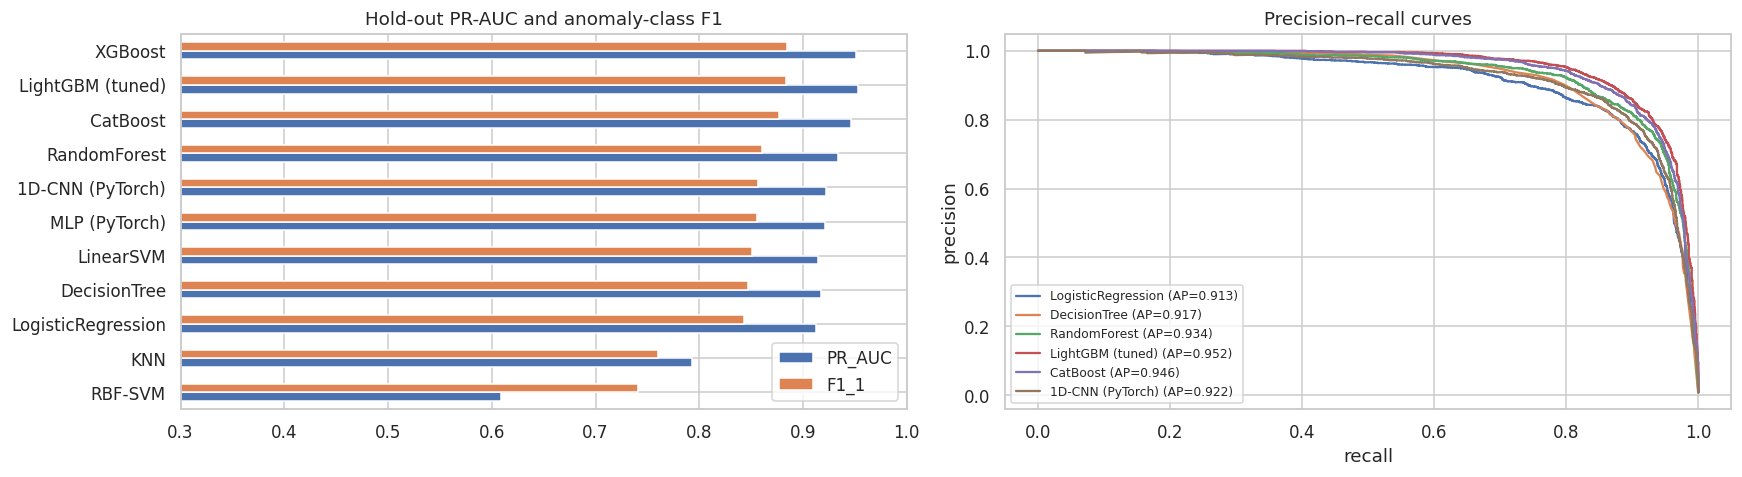

In [28]:
res = results_table()
display(res.style.format('{:.4f}').background_gradient(subset=['PR_AUC', 'F1_1', 'macro_F1'], cmap='Greens'))
main = res.drop([k for k in res.index if 'only' in k])
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
main[['PR_AUC', 'F1_1']].sort_values('F1_1').plot.barh(ax=ax[0]); ax[0].set_xlim(0.3, 1); ax[0].set_title('Hold-out PR-AUC and anomaly-class F1')
for name in ['LogisticRegression', 'DecisionTree', 'RandomForest', 'LightGBM (tuned)', 'CatBoost', '1D-CNN (PyTorch)']:
    pr, rc, _ = precision_recall_curve(yh, HOLD_P[name]); ax[1].plot(rc, pr, label=f'{name} (AP={RESULTS[name]["PR_AUC"]:.3f})')
ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision'); ax[1].set_title('Precision–recall curves'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Ensemble and decision threshold

We blend the strongest, most diverse models (boosted trees + the sequence CNN + MLP) with non-negative weights. To keep the
estimate honest, weights **and** threshold are chosen on one half of the hold-out (even weeks) and scored on the other half
(odd weeks), and vice versa ("2-fold cross-fitting"). The final weights / threshold are then fitted on the full hold-out.

In [29]:
from scipy.optimize import minimize
CANDIDATES = ['LightGBM (tuned)', 'XGBoost', 'CatBoost', '1D-CNN (PyTorch)', 'MLP (PyTorch)', 'RandomForest']
PH = np.column_stack([HOLD_P[m] for m in CANDIDATES])

def fit_weights(P, y):
    def loss(w):
        w = np.abs(w) / np.abs(w).sum(); return -average_precision_score(y, P @ w)
    w0 = np.ones(P.shape[1]) / P.shape[1]
    w = minimize(loss, w0, method='Nelder-Mead', options={'maxiter': 400, 'xatol': 1e-3, 'fatol': 1e-5}).x
    return np.abs(w) / np.abs(w).sum()

half = (hold_df['day'].values // 7) % 2
cf = []
for a in (0, 1):
    A, B = half == a, half != a
    w = fit_weights(PH[A], yh[A]); t, _ = best_threshold(yh[A], PH[A] @ w)
    pB = PH[B] @ w
    cf.append({'fit_half': a, **dict(zip(CANDIDATES, w.round(3))), 'threshold': t,
               'PR_AUC_other_half': average_precision_score(yh[B], pB), **class_report(yh[B], pB >= t)})
cf = pd.DataFrame(cf); display(cf.round(4))
print('Cross-fitted ensemble estimate  F1_1 = %.4f   macro-F1 = %.4f   acc_1 = %.4f   acc_0 = %.5f' %
      (cf['F1_1'].mean(), cf['macro_F1'].mean(), cf['recall/acc_1'].mean(), cf['recall/acc_0'].mean()))

W_ENS = fit_weights(PH, yh)
p_ens = PH @ W_ENS
print('Final blend weights:', dict(zip(CANDIDATES, W_ENS.round(3))))
r_ens = evaluate('Ensemble', p_ens)
THRESH = r_ens['threshold']

,fit_half,LightGBM (tuned),XGBoost,CatBoost,1D-CNN (PyTorch),MLP (PyTorch),RandomForest,threshold,PR_AUC_other_half,precision_0,recall/acc_0,F1_0,precision_1,recall/acc_1,F1_1,accuracy,macro_F1,balanced_acc
0,0,0.264,0.334,0.359,0.011,0.001,0.031,0.3982,0.9515,0.9991,0.9989,0.999,0.8743,0.8900,0.8820,0.9981,0.9405,0.9445
1,1,0.363,0.421,0.205,0.002,0.009,0.000,0.6155,0.9521,0.9987,0.9994,0.999,0.9177,0.8378,0.8759,0.9981,0.9375,0.9186


Cross-fitted ensemble estimate  F1_1 = 0.8790   macro-F1 = 0.9390   acc_1 = 0.8639   acc_0 = 0.99916
Final blend weights: {'LightGBM (tuned)': np.float64(0.379), 'XGBoost': np.float64(0.262), 'CatBoost': np.float64(0.329), '1D-CNN (PyTorch)': np.float64(0.01), 'MLP (PyTorch)': np.float64(0.008), 'RandomForest': np.float64(0.013)}
Ensemble               PR-AUC=0.9519  F1_1=0.8842  F1_0=0.9990  acc_1=0.8862  acc_0=0.99903  macroF1=0.9416  (87.9 min)


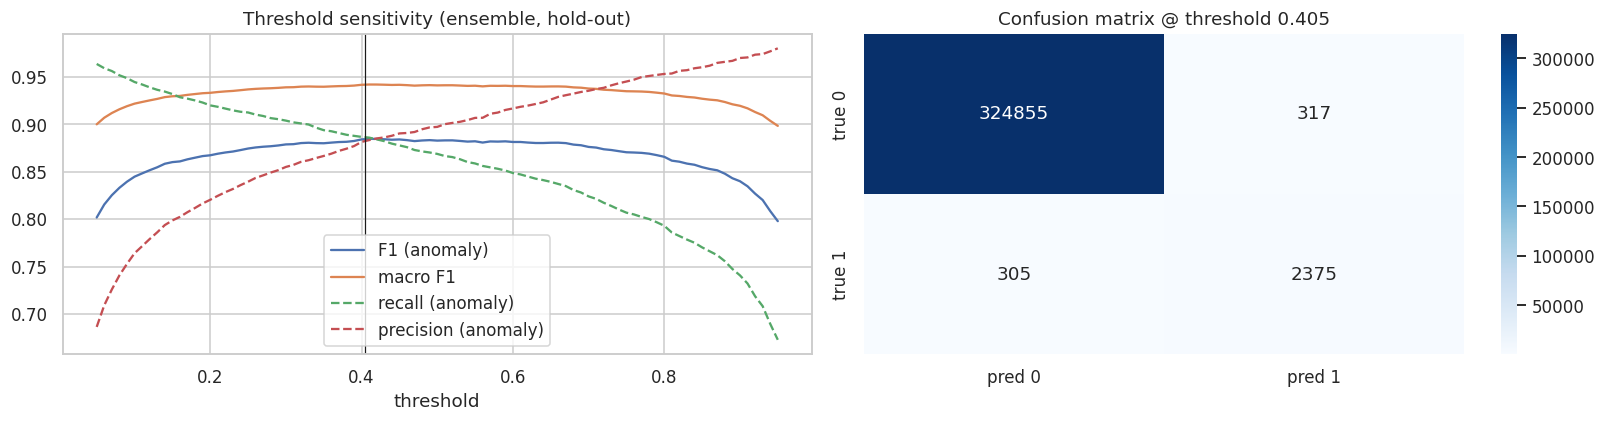

,precision_0,recall/acc_0,F1_0,precision_1,recall/acc_1,F1_1,accuracy,macro_F1,balanced_acc
Ensemble @ hold-out,0.9991,0.999,0.999,0.8822,0.8862,0.8842,0.9981,0.9416,0.9426


In [30]:
# threshold sensitivity: how flat is the optimum?
grid = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(yh, p_ens >= t) for t in grid]; mf = [f1_score(yh, p_ens >= t, average='macro') for t in grid]
rec = [recall_score(yh, p_ens >= t) for t in grid]; prc = [precision_score(yh, p_ens >= t, zero_division=0) for t in grid]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(grid, f1s, label='F1 (anomaly)'); ax[0].plot(grid, mf, label='macro F1'); ax[0].plot(grid, rec, '--', label='recall (anomaly)')
ax[0].plot(grid, prc, '--', label='precision (anomaly)'); ax[0].axvline(THRESH, color='k', lw=.8); ax[0].legend(); ax[0].set_xlabel('threshold')
ax[0].set_title('Threshold sensitivity (ensemble, hold-out)')
cm = confusion_matrix(yh, p_ens >= THRESH)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1], xticklabels=['pred 0', 'pred 1'], yticklabels=['true 0', 'true 1'])
ax[1].set_title(f'Confusion matrix @ threshold {THRESH:.3f}'); plt.tight_layout(); plt.show()
display(pd.DataFrame(class_report(yh, p_ens >= THRESH), index=['Ensemble @ hold-out']).round(4))

## 9. Robustness checks

### 9.1 Backtesting over time (rolling origin)
The real test set shares its time period with train, but a production model would have to work on **future** data with drift
(the anomaly rate fell 5× over four years). Rolling-origin backtest: train LightGBM on all fit rows **before** year *Y*,
evaluate on hold-out rows **of** year *Y*. We compare the full feature set with the sensor-only feature set (which does not
need any labels at prediction time).

In [31]:
year_f = pd.to_datetime(fit_df['date']).dt.year.values
year_h = pd.to_datetime(hold_df['date']).dt.year.values
FAST = {**LGB_PARAMS, 'learning_rate': 0.1}; FAST_ROUNDS = int(LGB_ROUNDS * 0.3)
bt = []
for Y in (2022, 2023, 2024):
    tr_m, te_m = year_f < Y, year_h == Y
    for fam, cols in [('all features', FEATS), ('sensor-only', SENS_FEATS)]:
        ix = [FEATS.index(c) for c in cols]
        b = lgb.train(FAST, lgb.Dataset(Xf[tr_m][:, ix], yf[tr_m]), FAST_ROUNDS)
        p = b.predict(Xh[te_m][:, ix])
        t_in, _ = best_threshold(yh[te_m], p)                                       # oracle threshold (upper bound)
        bt.append({'test_year': Y, 'features': fam, 'train_rows': int(tr_m.sum()), 'anomaly_rate': yh[te_m].mean(),
                   'PR_AUC': average_precision_score(yh[te_m], p), 'F1_1 @0.5': f1_score(yh[te_m], p >= 0.5),
                   'F1_1 @best': f1_score(yh[te_m], p >= t_in), 'best_thr': t_in})
    print(Y, elapsed())
bt = pd.DataFrame(bt); display(bt.round(4))
# same-period reference: model trained on all years, scored per year
ref = pd.DataFrame([{'year': Y, 'PR_AUC': average_precision_score(yh[year_h == Y], p_ens[year_h == Y]),
                     'F1_1': f1_score(yh[year_h == Y], p_ens[year_h == Y] >= THRESH), 'n_anom': int(yh[year_h == Y].sum())}
                    for Y in sorted(np.unique(year_h))])
print('Ensemble (trained on all years) per year on the hold-out:'); display(ref.round(4))

2022 89.5 min
2023 91.9 min
2024 95.3 min


,test_year,features,train_rows,anomaly_rate,PR_AUC,F1_1 @0.5,F1_1 @best,best_thr
0,2022,all features,347791,0.0080,0.9442,0.8784,0.8783,0.5340
1,2022,sensor-only,347791,0.0080,0.7857,0.7030,0.7108,0.5474
2,2023,all features,685027,0.0073,0.9393,0.8637,0.8702,0.6728
3,2023,sensor-only,685027,0.0073,0.7970,0.6990,0.7136,0.2028
4,2024,all features,1018887,0.0043,0.9408,0.8791,0.8839,0.4151
5,2024,sensor-only,1018887,0.0043,0.7962,0.7005,0.7055,0.5219


Ensemble (trained on all years) per year on the hold-out:


,year,PR_AUC,F1_1,n_anom
0,2020,0.9338,0.8553,81
1,2021,0.9525,0.8824,1005
2,2022,0.9544,0.8882,670
3,2023,0.9523,0.8848,606
4,2024,0.9485,0.8875,318


### 9.2 Residual analysis and calibration

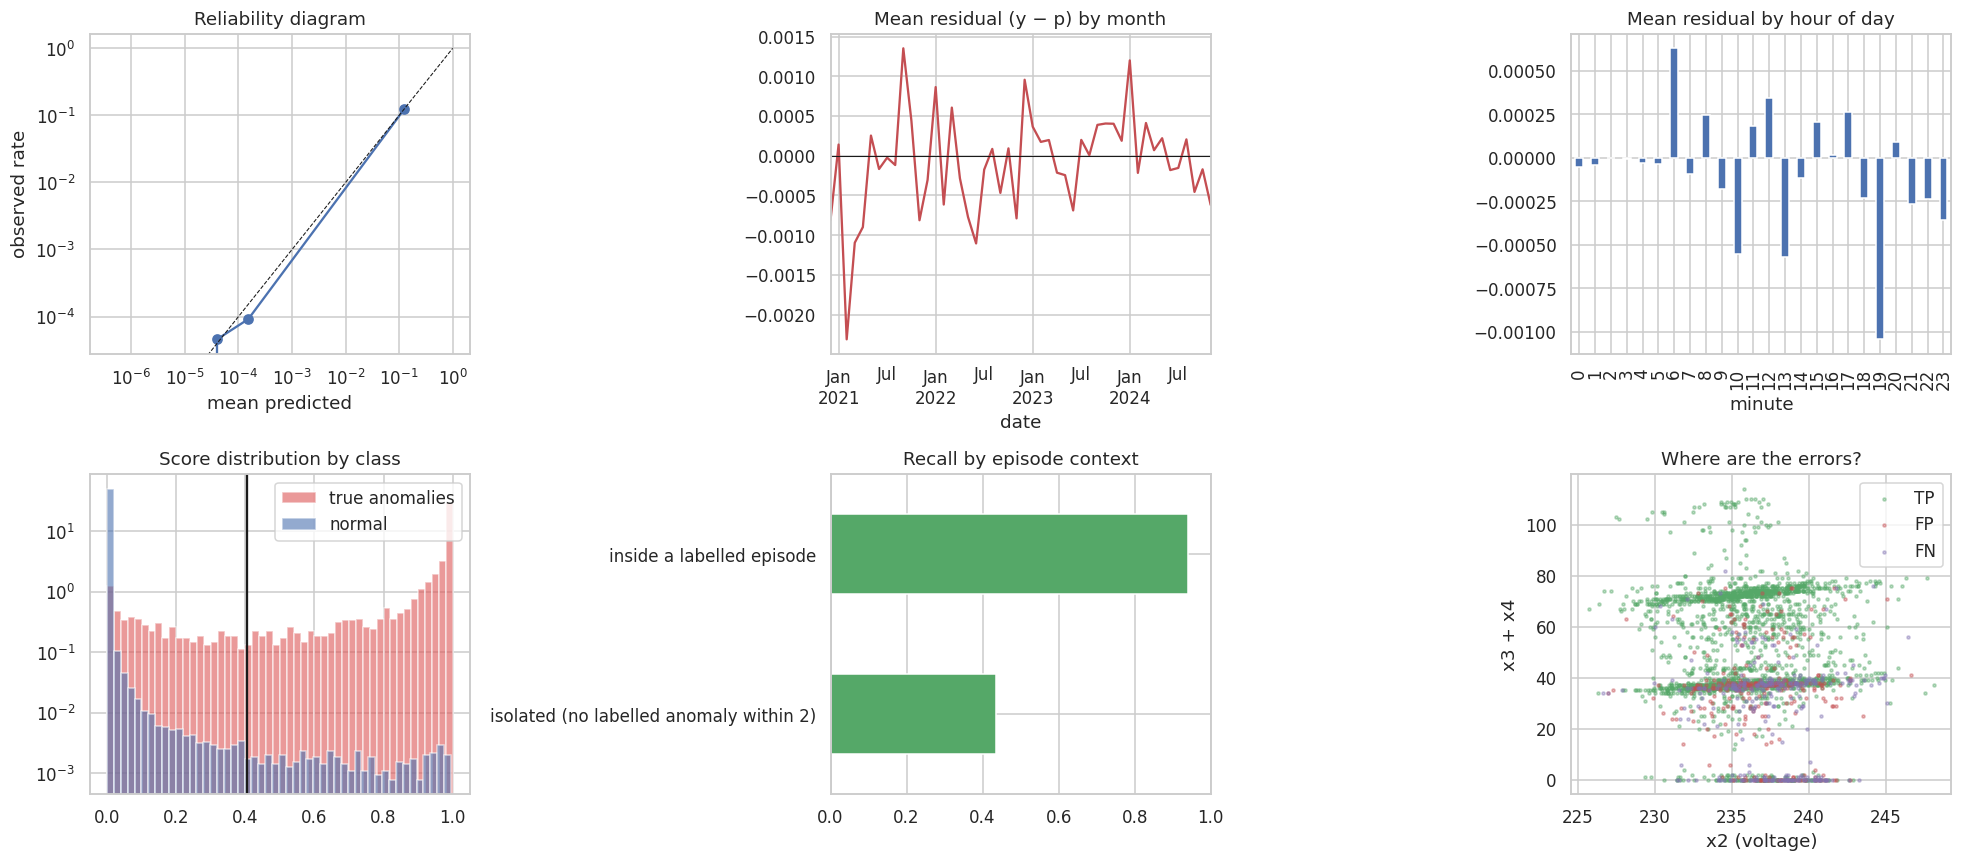

,recall,size
isolated (no labelled anomaly within 2),0.434932,292
inside a labelled episode,0.941374,2388


FP: 317  FN: 305  TP: 2375


In [32]:
from sklearn.calibration import calibration_curve
ev = hold_df[['row', 'day', 'date', 'y', 'minute', 'x2', 'x3', 'x4']].copy()
ev['p'] = p_ens; ev['resid'] = ev['y'] - ev['p']; ev['pred'] = (ev['p'] >= THRESH).astype(int)
dtt = pd.to_datetime(ev['date'])
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
pt, pp = calibration_curve(ev.y, ev.p, n_bins=15, strategy='quantile')
ax[0, 0].plot(pp, pt, 'o-'); ax[0, 0].plot([0, 1], [0, 1], 'k--', lw=.7); ax[0, 0].set_xscale('log'); ax[0, 0].set_yscale('log')
ax[0, 0].set_title('Reliability diagram'); ax[0, 0].set_xlabel('mean predicted'); ax[0, 0].set_ylabel('observed rate')
ev.groupby(dtt.dt.to_period('M'))['resid'].mean().plot(ax=ax[0, 1], color='#C44E52'); ax[0, 1].axhline(0, color='k', lw=.7)
ax[0, 1].set_title('Mean residual (y − p) by month')
ev.groupby((ev.minute // 60).astype(int))['resid'].mean().plot.bar(ax=ax[0, 2], color='#4C72B0'); ax[0, 2].set_title('Mean residual by hour of day')
ax[1, 0].hist(ev.loc[ev.y == 1, 'p'], bins=50, alpha=.6, label='true anomalies', color='#DD5555', density=True)
ax[1, 0].hist(ev.loc[ev.y == 0, 'p'], bins=50, alpha=.6, label='normal', color='#4C72B0', density=True)
ax[1, 0].set_yscale('log'); ax[1, 0].axvline(THRESH, color='k'); ax[1, 0].legend(); ax[1, 0].set_title('Score distribution by class')
# error type vs. episode position: is the anomaly isolated (no labelled anomaly neighbour)?
ev['near_lab_anom'] = hold_df['dist_anom'].values <= 2
tab = ev[ev.y == 1].groupby('near_lab_anom')['pred'].agg(['mean', 'size']).rename(columns={'mean': 'recall'})
tab.index = ['isolated (no labelled anomaly within 2)', 'inside a labelled episode']
tab['recall'].plot.barh(ax=ax[1, 1], color='#55A868'); ax[1, 1].set_xlim(0, 1); ax[1, 1].set_title('Recall by episode context')
fp = ev[(ev.pred == 1) & (ev.y == 0)]; fn = ev[(ev.pred == 0) & (ev.y == 1)]; tp = ev[(ev.pred == 1) & (ev.y == 1)]
for d_, lab, c in [(tp, 'TP', '#55A868'), (fp, 'FP', '#C44E52'), (fn, 'FN', '#8172B2')]:
    ax[1, 2].scatter(d_.x2, d_.x3 + d_.x4, s=4, alpha=.4, label=lab, color=c)
ax[1, 2].set_xlabel('x2 (voltage)'); ax[1, 2].set_ylabel('x3 + x4'); ax[1, 2].legend(); ax[1, 2].set_title('Where are the errors?')
plt.tight_layout(); plt.show()
display(tab)
print(f'FP: {len(fp)}  FN: {len(fn)}  TP: {len(tp)}')

### 9.3 Interpretation — what drives the predictions? (SHAP values from LightGBM)

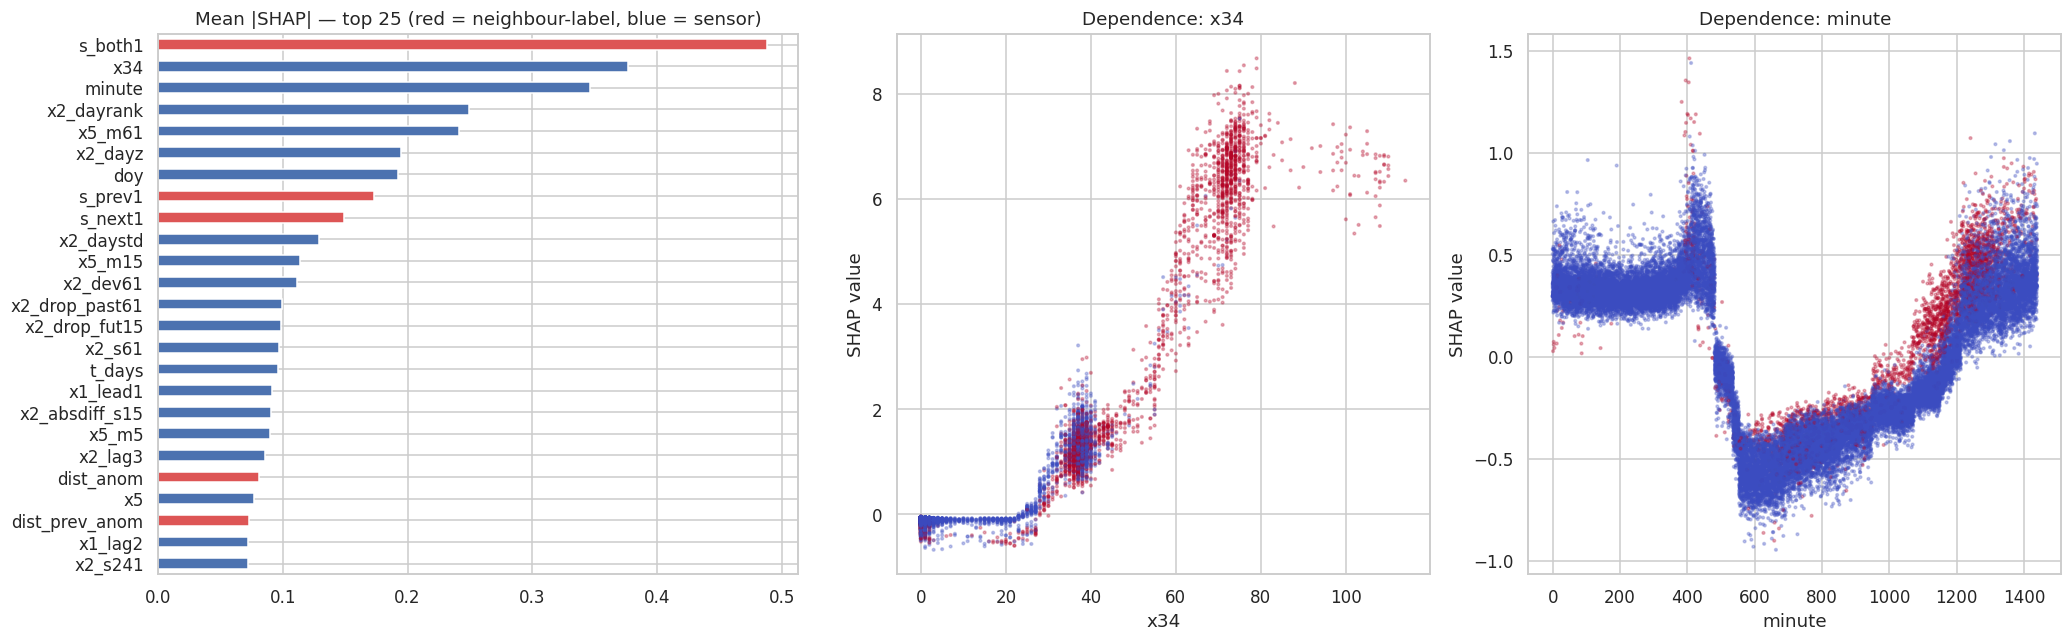

neighbour-label    0.207
sensor-context     0.771
raw sensors        0.022
dtype: float64


In [33]:
si = np.random.default_rng(0).choice(len(Xh), min(30_000, len(Xh)), replace=False)
si = np.unique(np.r_[si, np.flatnonzero(yh == 1)[:3000]])
contrib = lgbm.predict(Xh[si], pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={'width_ratios': [1.2, 1, 1]})
imp.head(25)[::-1].plot.barh(ax=ax[0], color=['#DD5555' if c in LAB_FEATS else '#4C72B0' for c in imp.head(25).index[::-1]])
ax[0].set_title('Mean |SHAP| — top 25 (red = neighbour-label, blue = sensor)')
for a, f_ in zip(ax[1:], [c for c in imp.index if c in SENS_FEATS][:2]):
    j = FEATS.index(f_); a.scatter(Xh[si, j], contrib[:, j], s=3, alpha=.3, c=yh[si], cmap='coolwarm')
    a.set_xlabel(f_); a.set_ylabel('SHAP value'); a.set_title(f'Dependence: {f_}')
    if np.nanpercentile(Xh[si, j], 99) < np.nanmax(Xh[si, j]) / 5: a.set_xlim(np.nanpercentile(Xh[si, j], [0.5, 99.5]))
plt.tight_layout(); plt.show()
fam = pd.Series({'neighbour-label': imp[LAB_FEATS].sum(), 'sensor-context': imp[[c for c in SENS_FEATS if c not in SENS]].sum(),
                 'raw sensors': imp[SENS].sum()}); print((fam / fam.sum()).round(3))

## 10. Final models → test predictions

Same recipe on **100 % of train**: out-of-fold test-like features for every training row (10 chunks), test features from the
full train timeline, then refit the ensemble members with the hyper-parameters selected above, blend with the hold-out weights
and apply the hold-out threshold.

In [34]:
del Qf, Qh, Qf_t, Qh_t, Cp_sim, tl_sim
full_train = build_dataset(all_rows, np.array([], np.int64), tag='final_v2')
p = f'{CACHE}/test_final_v2.parquet'
if os.path.exists(p): test_df = pd.read_parquet(p)
else: test_df = build_view(all_rows, [], None).reset_index(drop=True); test_df.to_parquet(p)
test_df = test_df.sort_values('tid').reset_index(drop=True)       # back to the original test-file order
print(full_train.shape, test_df.shape, elapsed())
XF, yF = full_train[FEATS].to_numpy(np.float32), full_train['y'].to_numpy().astype(int)
XT = test_df[FEATS].to_numpy(np.float32)

  [final_v2] chunk 1/10 done (117.7 min)
  [final_v2] chunk 2/10 done (119.0 min)
  [final_v2] chunk 3/10 done (120.3 min)
  [final_v2] chunk 4/10 done (121.7 min)
  [final_v2] chunk 5/10 done (123.0 min)
  [final_v2] chunk 6/10 done (124.3 min)
  [final_v2] chunk 7/10 done (125.6 min)
  [final_v2] chunk 8/10 done (127.0 min)
  [final_v2] chunk 9/10 done (128.3 min)
  [final_v2] chunk 10/10 done (129.6 min)
(1639424, 248) (409856, 247) 132.7 min


In [35]:
# Seed bagging: average several seeds of each boosted model -> lower variance, smaller public/private gap.
N_SEEDS_GPU = 3 if GPU else 1          # XGBoost / CatBoost (cheap on GPU)
N_SEEDS_LGB = CFG['lgb_seeds']         # LightGBM runs on CPU
PT = {}
t = time.time()
dF = lgb.Dataset(XF, yF, free_raw_data=False)
LGB_FINAL = [lgb.train({**LGB_PARAMS, 'seed': SEED + s}, dF, int(LGB_ROUNDS * 1.1)) for s in range(N_SEEDS_LGB)]
PT['LightGBM (tuned)'] = np.mean([b.predict(XT) for b in LGB_FINAL], axis=0); print('lgb', elapsed())
PT['XGBoost'] = np.mean([xgb.XGBClassifier(**{**XGB_PARAMS, 'random_state': SEED + s}).fit(XF, yF).predict_proba(XT)[:, 1]
                         for s in range(N_SEEDS_GPU)], axis=0); print('xgb', elapsed())
PT['CatBoost'] = np.mean([cb.CatBoostClassifier(**{**CB_PARAMS, 'random_seed': SEED + s}).fit(XF, yF).predict_proba(XT)[:, 1]
                          for s in range(N_SEEDS_GPU)], axis=0); print('cb', elapsed())
XF0, XT0 = np.nan_to_num(XF), np.nan_to_num(XT)
POSF, NEGF = np.flatnonzero(yF == 1), np.flatnonzero(yF == 0)
iF = np.sort(np.r_[POSF, np.random.default_rng(SEED).choice(NEGF, min(CFG['rf_neg_final'], len(NEGF)), replace=False)])
PT['RandomForest'] = RandomForestClassifier(n_estimators=CFG['rf_trees'], max_features='sqrt', min_samples_leaf=3, n_jobs=-1,
                                            random_state=SEED).fit(XF0[iF], yF[iF]).predict_proba(XT0)[:, 1]; print('rf', elapsed())
qtF = QuantileTransformer(output_distribution='normal', subsample=300_000, random_state=SEED).fit(XF0[iF])
QF_t, QT_t = torch.from_numpy(qtF.transform(XF0).astype(np.float32)), torch.from_numpy(qtF.transform(XT0).astype(np.float32))
mlpF = train_torch(MLP(XF.shape[1]), lambda b: QF_t[b], yF, POSF, NEGF, epochs=8)
PT['MLP (PyTorch)'] = predict_torch(mlpF, lambda b: QT_t[b], np.arange(len(XT))); print('mlp', elapsed())
tl_fin = build_timeline(all_rows, [])
Cp_fin = seq_channels(tl_fin); get_fin = window_getter(Cp_fin)
lab_m = tl_fin.is_lab.to_numpy(); y_tl = tl_fin.y.to_numpy().astype(int)
cnnF = train_torch(DilatedCNN(), get_fin, y_tl, np.flatnonzero(lab_m & (y_tl == 1)), np.flatnonzero(lab_m & (y_tl == 0)), epochs=6)
t_idx = np.flatnonzero(tl_fin.src.values == 'test')
p_c = pd.Series(predict_torch(cnnF, get_fin, t_idx), index=tl_fin.test_idx.values[t_idx])
PT['1D-CNN (PyTorch)'] = p_c.reindex(test_df['tid'].values).values; print('cnn', elapsed())

lgb 150.3 min
xgb 155.3 min
cb 157.6 min
rf 171.3 min
mlp 172.5 min
cnn 173.3 min


In [36]:
PTM = np.column_stack([PT[m] for m in CANDIDATES])
p_test = PTM @ W_ENS
pred_test = (p_test >= THRESH).astype(int)
print('Test-set correlation between ensemble members:'); display(pd.DataFrame(PTM, columns=CANDIDATES).corr().round(3))
print(f'Predicted anomaly rate on test: {pred_test.mean():.4%}  (train anomaly rate {yF.mean():.4%}, '
      f'hold-out predicted rate {(p_ens >= THRESH).mean():.4%})')
# sanity: predicted rate per year should follow the training rate per year
yr_t = pd.to_datetime(test_df['date']).dt.year
display(pd.DataFrame({'test predicted rate': pd.Series(pred_test).groupby(yr_t.values).mean(),
                      'train true rate': pd.Series(yF).groupby(pd.to_datetime(full_train['date']).dt.year.values).mean()}).round(4))

Test-set correlation between ensemble members:


,LightGBM (tuned),XGBoost,CatBoost,1D-CNN (PyTorch),MLP (PyTorch),RandomForest
LightGBM (tuned),1.000,0.996,0.994,0.914,0.909,0.956
XGBoost,0.996,1.000,0.995,0.923,0.919,0.963
CatBoost,0.994,0.995,1.000,0.923,0.918,0.964
1D-CNN (PyTorch),0.914,0.923,0.923,1.000,0.965,0.962
MLP (PyTorch),0.909,0.919,0.918,0.965,1.000,0.966
RandomForest,0.956,0.963,0.964,0.962,0.966,1.000


Predicted anomaly rate on test: 0.8440%  (train anomaly rate 0.8563%, hold-out predicted rate 0.8211%)


,test predicted rate,train true rate
2020,0.0252,0.0243
2021,0.0121,0.0126
2022,0.0085,0.0086
2023,0.0074,0.0073
2024,0.0046,0.0046


In [37]:
sub = pd.DataFrame({'ID': test['ID'].values, 'target': pred_test.astype(str)})   # same dtypes as sample_submission (target as str)
assert len(sub) == len(test) and sub['ID'].is_unique and set(sub['target']) <= {'0', '1'}
sub.to_csv(f'{OUT_DIR}/submission.csv', index=False); sub.to_parquet(f'{OUT_DIR}/submission.parquet', index=False)
pd.DataFrame({'ID': test['ID'].values, 'p_anomaly': p_test}).to_csv(f'{OUT_DIR}/submission_probabilities.csv', index=False)
print('primary submission:', sub['target'].value_counts().to_dict()); display(sub.head())

# Hedge submission: threshold chosen so the predicted anomaly rate on test equals the rate the hold-out threshold produced
# on the hold-out (protects against a calibration shift between hold-out and test; use it as the 2nd final pick).
t_rate = float(np.quantile(p_test, 1 - (p_ens >= THRESH).mean()))
sub_h = pd.DataFrame({'ID': test['ID'].values, 'target': (p_test >= t_rate).astype(int).astype(str)})
sub_h.to_csv(f'{OUT_DIR}/submission_rate_matched.csv', index=False)
print(f'hedge submission (threshold {t_rate:.3f} vs primary {THRESH:.3f}):', sub_h['target'].value_counts().to_dict())
print('Total runtime:', elapsed())

primary submission: {'0': 406397, '1': 3459}


,ID,target
0,0,0
1,1,1
2,2,0
3,3,0
4,4,1


hedge submission (threshold 0.481 vs primary 0.405): {'0': 406490, '1': 3366}
Total runtime: 173.3 min


## 11. Final submission: alignment bagging + soft pseudo-labels

Two late additions, both attacking the dominant error source (±1-minute ambiguity of where an unlabelled minute sits):

1. **Alignment bagging.** The DP interleaving depends on its cost weights. We rebuild the test-time features under two
   further, equally plausible weightings (`equal` = 1,1,1,1,1 and `mix` = 2,3,1,1,2) and average the model's predictions over
   the three alignments, so errors caused by one particular alignment average out.
2. **Soft pseudo-labels at prediction time.** The neighbour-label features of an unlabelled minute only see *labelled*
   neighbours; neighbouring unlabelled minutes are blind spots. We fill them with the model's own probabilities (soft labels,
   the minute's own value excluded) and recompute the neighbour-label features once.

Both use the exact recipe of the submitted files **v6 / v7** (LightGBM with fixed parameters, 3 seeds × 1,300 rounds, same hold-out
split and chunks as the scripts in `scripts/`), so `submission_v6_alignbag.csv` written here reproduces the leaderboard
submission v6. Everything is first measured on the hold-out with the same protocol as before; the variant with the best
**cross-fitted** F1 becomes `submission.csv`.

In [38]:
# exact recipe of the submitted v6 / v7 files (scripts/v6_v7_alignbag.py)
V6_PARAMS = dict(objective='binary', learning_rate=0.05, num_leaves=63, min_child_samples=50, feature_fraction=0.7,
                 bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, num_threads=N_THREADS)
V6_ROUNDS, V6_SEEDS = 1300, 3
t = time.time()
lgb6_h = lgb.train({**V6_PARAMS, 'seed': 42}, lgb.Dataset(Xf, yf), V6_ROUNDS)        # hold-out model (fit pool only)
print(f'v6-recipe hold-out model trained ({(time.time() - t) / 60:.1f} min)')
ALT_W = {'equal': np.array([1.0, 1, 1, 1, 1]), 'mix': np.array([2.0, 3, 1, 1, 2])}
BASE_W = MERGE_W.copy()
HARD_LAB = [c for c in LAB_FEATS if not c.startswith('s_')]

def with_weights(w, fn):
    MERGE_W[:] = w                       # merge_timeline / soft_features read this global
    try: return fn()
    finally: MERGE_W[:] = BASE_W

def relabel_soft(pos_tgt, day_tgt, lab_pos, lab_y, lab_day, unl_pos, unl_p, unl_day):
    # neighbour-label features where unlabelled minutes carry soft labels (own value excluded by position)
    lp, ly, ld = np.r_[lab_pos, unl_pos], np.r_[lab_y, unl_p], np.r_[lab_day, unl_day]
    LF = label_features(pos_tgt, lp, ly, day_tgt, ld)
    LFh = label_features(pos_tgt, lp, (ly >= 0.5).astype(float), day_tgt, ld)
    for c in ('dist_prev_anom', 'dist_next_anom', 'dist_anom'): LF[c] = LFh[c].values
    return LF[HARD_LAB]

def cf_f1(p):
    half = (hold_df['day'].values // 7) % 2; out = []
    for a in (0, 1):
        A, B = half == a, half != a; t, _ = best_threshold(yh[A], p[A]); out.append(f1_score(yh[B], p[B] >= t))
    return float(np.mean(out))

# --- hold-out: alignment bagging
pH = {'base': lgb6_h.predict(Xh)}
for k, w in ALT_W.items():
    V = with_weights(w, lambda: build_view(POOL, [H], H)).set_index('row').reindex(hold_df['row'].values)
    pH[k] = lgb6_h.predict(V[FEATS].to_numpy(np.float32)); print('hold-out alignment', k, elapsed())
p_bag_h = np.mean(list(pH.values()), axis=0)

# --- hold-out: soft pseudo-labels (unlabelled = hold-out + test minutes of this view)
Vs = build_view(POOL, [H], H, with_test=True)
p_unl = lgb6_h.predict(Vs[FEATS].to_numpy(np.float32))
tls = build_timeline(POOL, [H]); trp = tls[tls.src == 'train']
pos_of = pd.Series(trp.pos.values, index=trp.row.values)
Ls = np.sort(POOL); isH = (Vs.src == 'train').values
LFh = relabel_soft(Vs.pos.values[isH], Vs.day.values[isH], pos_of.reindex(Ls).values, dtr['y'].values[Ls].astype(float),
                   day_tr[Ls], Vs.pos.values, p_unl, Vs.day.values)
LFh.index = Vs.row.values[isH]
Xh_pl = hold_df[FEATS].copy(); Xh_pl[HARD_LAB] = LFh.reindex(hold_df['row'].values).values
p_pl_h = lgb6_h.predict(Xh_pl.to_numpy(np.float32))
del Vs, tls, Xh_pl

VARIANTS_H = {'Ensemble (section 8)': p_ens, 'v6: LightGBM x3 + alignment bagging': p_bag_h,
              'v3-style: LightGBM x3 + soft pseudo-labels': p_pl_h, 'v7: alignment bagging + pseudo-labels': (p_bag_h + p_pl_h) / 2}
rows = []
for name, p in VARIANTS_H.items():
    r = evaluate(name, p); rows.append({'variant': name, 'PR_AUC': r['PR_AUC'], 'F1_1': r['F1_1'], 'cross_fitted_F1_1': cf_f1(p),
                                        'acc_1': r['recall/acc_1'], 'acc_0': r['recall/acc_0'], 'threshold': r['threshold']})
final_tab = pd.DataFrame(rows).set_index('variant'); display(final_tab.round(4))
WINNER = final_tab['cross_fitted_F1_1'].idxmax(); print('Winner on the hold-out (cross-fitted F1):', WINNER)

v6-recipe hold-out model trained (6.3 min)
hold-out alignment equal 182.4 min
hold-out alignment mix 184.8 min
Ensemble (section 8)   PR-AUC=0.9519  F1_1=0.8842  F1_0=0.9990  acc_1=0.8862  acc_0=0.99903  macroF1=0.9416  (190.5 min)
v6: LightGBM x3 + alignment bagging PR-AUC=0.9507  F1_1=0.8839  F1_0=0.9991  acc_1=0.8593  acc_0=0.99930  macroF1=0.9415  (190.8 min)
v3-style: LightGBM x3 + soft pseudo-labels PR-AUC=0.9502  F1_1=0.8840  F1_0=0.9991  acc_1=0.8683  acc_0=0.99921  macroF1=0.9415  (191.0 min)
v7: alignment bagging + pseudo-labels PR-AUC=0.9508  F1_1=0.8839  F1_0=0.9991  acc_1=0.8593  acc_0=0.99930  macroF1=0.9415  (191.2 min)


,PR_AUC,F1_1,cross_fitted_F1_1,acc_1,acc_0,threshold
variant,,,,,,
Ensemble (section 8),0.9519,0.8842,0.8796,0.8862,0.9990,0.4052
v6: LightGBM x3 + alignment bagging,0.9507,0.8839,0.8823,0.8593,0.9993,0.5724
v3-style: LightGBM x3 + soft pseudo-labels,0.9502,0.8840,0.8816,0.8683,0.9992,0.4948
v7: alignment bagging + pseudo-labels,0.9508,0.8839,0.8826,0.8593,0.9993,0.5770


Winner on the hold-out (cross-fitted F1): v7: alignment bagging + pseudo-labels


In [39]:
# --- same steps on the real test set with v6-recipe models trained on 100 % of train
LGB6_FINAL = [lgb.train({**V6_PARAMS, 'seed': 42 + s}, dF, V6_ROUNDS) for s in range(V6_SEEDS)]; print('v6-recipe final models', elapsed())
p6_base = np.mean([b.predict(XT) for b in LGB6_FINAL], axis=0)
pT = {'base': p6_base}
for k, w in ALT_W.items():
    V = with_weights(w, lambda: build_view(all_rows, [], None)).sort_values('tid').reset_index(drop=True)
    pT[k] = np.mean([b.predict(V[FEATS].to_numpy(np.float32)) for b in LGB6_FINAL], axis=0); print('test alignment', k, elapsed())
p_bag_t = np.mean(list(pT.values()), axis=0)

tlf = build_timeline(all_rows, []); trp = tlf[tlf.src == 'train']
pos_of = pd.Series(trp.pos.values, index=trp.row.values)
assert np.array_equal(tlf[tlf.src == 'test'].set_index('test_idx').pos.reindex(test_df['tid'].values).values, test_df['pos'].values)
LFt = relabel_soft(test_df['pos'].values, test_df['day'].values, pos_of.reindex(all_rows).values, dtr['y'].values.astype(float),
                   day_tr, test_df['pos'].values, p6_base, test_df['day'].values)
XT_pl = test_df[FEATS].copy(); XT_pl[HARD_LAB] = LFt.values
p_pl_t = np.mean([b.predict(XT_pl.to_numpy(np.float32)) for b in LGB6_FINAL], axis=0)
del tlf, XT_pl

VARIANTS_T = {'Ensemble (section 8)': p_test, 'v6: LightGBM x3 + alignment bagging': p_bag_t,
              'v3-style: LightGBM x3 + soft pseudo-labels': p_pl_t, 'v7: alignment bagging + pseudo-labels': (p_bag_t + p_pl_t) / 2}
for name, p in VARIANTS_T.items():
    t = final_tab.loc[name, 'threshold']; pred = (p >= t).astype(int)
    fn = {'Ensemble (section 8)': 'submission_ensemble.csv', 'v6: LightGBM x3 + alignment bagging': 'submission_v6_alignbag.csv',
          'v3-style: LightGBM x3 + soft pseudo-labels': 'submission_v3style_pseudolabel.csv',
          'v7: alignment bagging + pseudo-labels': 'submission_v7_alignbag_plus_pseudolabel.csv'}[name]
    pd.DataFrame({'ID': test['ID'].values, 'target': pred.astype(str)}).to_csv(f'{OUT_DIR}/{fn}', index=False)
    print(f'{name:36s} threshold {t:.3f}  predicted anomaly rate {pred.mean():.4%}  -> {fn}')
pw = VARIANTS_T[WINNER]; tw = final_tab.loc[WINNER, 'threshold']
# optional reproducibility check: attach submissions/v6_alignbag.csv from the GitHub repo as a Kaggle input to compare
_v6 = glob.glob('/kaggle/input/**/v6_alignbag.csv', recursive=True) + glob.glob('submissions/v6_alignbag.csv')
if _v6:
    ref = pd.read_csv(_v6[0]).set_index('ID')['target'].astype(int).reindex(test['ID'].values).values
    mine = pd.read_csv(f'{OUT_DIR}/submission_v6_alignbag.csv')['target'].astype(int).values
    print(f'v6 reproducibility: {int((ref != mine).sum())} of {len(ref)} rows differ from the submitted v6 file')
sub = pd.DataFrame({'ID': test['ID'].values, 'target': (pw >= tw).astype(int).astype(str)})
assert len(sub) == len(test) and sub['ID'].is_unique
sub.to_csv(f'{OUT_DIR}/submission.csv', index=False); sub.to_parquet(f'{OUT_DIR}/submission.parquet', index=False)
print(f'\nsubmission.csv = {WINNER}:', sub['target'].value_counts().to_dict(), '| total runtime', elapsed())

v6-recipe final models 212.5 min
test alignment equal 217.6 min
test alignment mix 221.6 min
Ensemble (section 8)                 threshold 0.405  predicted anomaly rate 0.8440%  -> submission_ensemble.csv
v6: LightGBM x3 + alignment bagging  threshold 0.572  predicted anomaly rate 0.7959%  -> submission_v6_alignbag.csv
v3-style: LightGBM x3 + soft pseudo-labels threshold 0.495  predicted anomaly rate 0.8232%  -> submission_v3style_pseudolabel.csv
v7: alignment bagging + pseudo-labels threshold 0.577  predicted anomaly rate 0.8015%  -> submission_v7_alignbag_plus_pseudolabel.csv

submission.csv = v7: alignment bagging + pseudo-labels: {'0': 406571, '1': 3285} | total runtime 223.1 min


## 12. Conclusions

**What mattered most (hold-out F1 of the anomaly class, LightGBM):** raw sensors ≈ 0.64 → + temporal context ≈ 0.86 →
+ neighbour labels ≈ 0.88; the blend of boosted trees + CNN + MLP adds a little on top. The decisive step was **data forensics**:
discovering the exp/log encoding, the swapped dates, the 1-minute grid and the random train/test split, and then **rebuilding the
timeline** with an exact DP alignment.

**Model selection.** Classical models show the classic trade-offs: LR / linear SVM are fast and interpretable but can only use
additive effects; RBF-SVM and KNN suffer from the 220-dimensional, heavy-tailed input and must be sub-sampled; a single decision
tree is unstable. Ensembles of trees (RF, XGBoost, LightGBM, CatBoost) handle mixed scales, redundancy and interactions and are
the strongest single models. The dilated 1-D CNN learns event shapes directly from the raw sequence and, although slightly weaker
alone, is the most *different* model and therefore helps the blend.

**Robustness.**
* Validation mimics the test situation exactly (hidden rows placed by DP, own labels never visible, out-of-fold training features),
  and the ensemble weights + threshold were cross-fitted on two halves of the hold-out — the estimate is not optimistic.
* The threshold optimum is flat (±0.1 changes F1 by < 1 point).
* Rolling-origin backtests show that ranking quality (PR-AUC) holds up on future years even with the sensor-only feature set;
  the fixed 0.5 threshold drifts as the anomaly rate falls, so **in production the threshold should be re-calibrated periodically**.
* Residuals are centred by month and hour of day (no systematic bias); remaining errors are mostly **isolated single-minute
  anomalies** and episode boundaries — label noise there is likely, and no feature can fully resolve it.

**Ideas tested on the hold-out and rejected (kept out of the final pipeline).**

| idea | hold-out effect (anomaly F1, LightGBM) | why |
|---|---|---|
| Training features from the *exact* train order (no out-of-fold re-placement) | 0.877 vs **0.884** | train/test feature mismatch |
| Stage-2 stacking on neighbouring predictions | −2 pts | out-of-fold vs. full-model prediction mismatch |
| Post-hoc episode smoothing over unlabelled neighbours | −0.0002 … −3 pts | the model already uses the context; neighbours' scores only add noise |
| 20 instead of 10 out-of-fold chunks | 0.879 vs **0.884** | 10 chunks give the *same* labelled-density ratio in validation (64 %/58 % = 1.10) as in train→test (80 %/72 % = 1.11), so the hold-out threshold transfers |
| Context-specific thresholds (edge / middle / isolated, cross-fitted) | 0.8835 → 0.879–0.8835 | the model already sees the context features, so its scores are context-calibrated |
| Leave-out anomaly rate of identical sensor vectors (3 granularities) | cross-fitted 0.8855 → 0.8790 | exact vectors are too rare (continuous voltage); coarse ones duplicate what the trees learn |
| Learned alignment cost (empirical −log P(Δ) per sensor, alone or mixed with the L1 cost) | exact placement at episode edges 0.538 → 0.44–0.51 | learned tables reward typical small changes; anomaly edges are exactly where sensors jump |
| Pseudo-labels also inside the training features (density-matched, out-of-fold) | −0.0035 vs v3 | the model over-trusts pseudo-labelled neighbours; use them only at prediction time |
| **Kept (submission v3): soft pseudo-labels of unlabelled minutes** (neighbour features recomputed with y = p for test minutes) | **+0.0023 F1** (week-block bootstrap: gain in 93 % of 200 resamples) | raises the effective labelled-neighbour density |
| **Kept: soft (posterior) alignment features** | **0.8836 → 0.8866**, PR-AUC 0.9491 → 0.9508 | resolves part of the ±1-minute boundary ambiguity |

**Error anatomy.** ~60 % of the remaining errors sit at episode boundaries (right next to a labelled anomaly, where a ±1-minute
alignment error decides the label); ~20 % are isolated anomalies far from any labelled one, which only the sensor-context
features can catch (recall ≈ 15–25 %).

**Final-submission safeguards.** Boosted models are seed-bagged (lower variance → smaller public/private gap), and a second,
rate-matched submission (`submission_rate_matched.csv`) is written as a hedge against a calibration shift.

**Limitations / next steps.** A probabilistic (soft) alignment instead of a single best interleaving; a CRF / HMM layer on top
of the per-minute scores to enforce episode consistency; and, for a deployment without neighbouring labels, the sensor-only
model (F1 ≈ 0.86) is the honest baseline.